# 0. Install dependencies

In [ ]:
!pip install lxml requests gender-guesser

# 1. Parse names

In [1]:
import os
import xml.etree.ElementTree as ET
from pathlib import Path
import pandas as pd

# Define the namespace
namespaces = {
    'tei': 'http://www.tei-c.org/ns/1.0',
    'telota': 'http://www.telota.de',
    'xs': 'http://www.w3.org/2001/XMLSchema'
}

# Define the path to the Personen directory (relative to notebook location)
personen_dir = Path('../data/raw/Register/Personen')

# Load all XML files and parse person entries
all_persons = []

for xml_file in personen_dir.glob('*.xml'):
    try:
        tree = ET.parse(xml_file)
        root = tree.getroot()
        
        # Find all person elements
        persons = root.findall('.//tei:person', namespaces)
        
        for person in persons:
            person_data = {
                'xml_id': person.get('{http://www.w3.org/XML/1998/namespace}id')
            }
            
            # Extract GND URI
            idno = person.find('tei:idno[@type="uri"]', namespaces)
            if idno is not None:
                person_data['gnd_uri'] = idno.text
            
            # Extract regular name (surname and forename)
            persName_reg = person.find('tei:persName[@type="reg"]', namespaces)
            if persName_reg is not None:
                surname = persName_reg.find('tei:surname', namespaces)
                forename = persName_reg.find('tei:forename', namespaces)
                person_data['surname'] = surname.text if surname is not None else None
                person_data['forename'] = forename.text if forename is not None else None
            
            # Extract alternative names
            alt_names = []
            for persName_alt in person.findall('tei:persName[@type="alt"]', namespaces):
                alt_name = {}
                subtype = persName_alt.get('subtype')
                if subtype:
                    alt_name['subtype'] = subtype
                
                # Check for surname/forename structure
                surname_alt = persName_alt.find('tei:surname', namespaces)
                forename_alt = persName_alt.find('tei:forename', namespaces)
                name_alt = persName_alt.find('tei:name', namespaces)
                
                if surname_alt is not None:
                    alt_name['surname'] = surname_alt.text
                if forename_alt is not None:
                    alt_name['forename'] = forename_alt.text
                if name_alt is not None:
                    alt_name['name'] = name_alt.text
                
                alt_names.append(alt_name)
            
            if alt_names:
                person_data['alt_names'] = alt_names
            
            # Extract birth and death years
            birth = person.find('tei:birth', namespaces)
            death = person.find('tei:death', namespaces)
            person_data['birth'] = birth.text if birth is not None and birth.text else None
            person_data['death'] = death.text if death is not None and death.text else None
            
            # Extract note
            note = person.find('tei:note', namespaces)
            person_data['note'] = note.text if note is not None else None
            
            all_persons.append(person_data)
        
        print(f"Loaded {len(persons)} persons from: {xml_file.name}")
        
    except ET.ParseError as e:
        print(f"Error parsing {xml_file.name}: {e}")

print(f"\nTotal persons loaded: {len(all_persons)}")

# Create DataFrame
df_persons = pd.DataFrame(all_persons)

print(f"\nDataFrame shape: {df_persons.shape}")
print(f"\nFirst few rows:")
print(df_persons.head())

Loaded 297 persons from: A.xml
Loaded 787 persons from: B.xml
Loaded 237 persons from: C.xml
Loaded 317 persons from: D.xml
Loaded 183 persons from: E.xml
Loaded 327 persons from: F.xml
Loaded 419 persons from: G.xml
Loaded 606 persons from: H.xml
Loaded 47 persons from: I.xml
Loaded 123 persons from: J.xml
Loaded 507 persons from: K.xml
Loaded 419 persons from: G.xml
Loaded 606 persons from: H.xml
Loaded 47 persons from: I.xml
Loaded 123 persons from: J.xml
Loaded 507 persons from: K.xml
Loaded 388 persons from: L.xml
Loaded 507 persons from: M.xml
Loaded 156 persons from: N.xml
Loaded 99 persons from: O.xml
Loaded 429 persons from: P.xml
Loaded 7 persons from: Q.xml
Loaded 388 persons from: L.xml
Loaded 507 persons from: M.xml
Loaded 156 persons from: N.xml
Loaded 99 persons from: O.xml
Loaded 429 persons from: P.xml
Loaded 7 persons from: Q.xml
Loaded 488 persons from: R.xml
Loaded 1182 persons from: S.xml
Loaded 251 persons from: T.xml
Loaded 48 persons from: U.xml
Loaded 123 perso

# 2. Get GND Gender-Data

In [2]:
import requests
import time
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

# Create a session with retry strategy
session = requests.Session()
retry_strategy = Retry(
    total=3,
    backoff_factor=1,
    status_forcelist=[429, 500, 502, 503, 504]
)
adapter = HTTPAdapter(max_retries=retry_strategy)
session.mount("http://", adapter)
session.mount("https://", adapter)

def get_gender_from_gnd(gnd_uri, max_retries=3):
    """
    Fetch gender information from GND URI using lobid-gnd API.
    Returns: 'male', 'female', 'unknown', or None if not found
    """
    if pd.isna(gnd_uri) or not gnd_uri:
        return None
    
    for attempt in range(max_retries):
        try:
            # Extract GND ID from URI (part after last slash)
            gnd_id = gnd_uri.rstrip('/').split('/')[-1]
            
            # Use lobid-gnd API for JSON response
            api_url = f"https://lobid.org/gnd/{gnd_id}.json"
            
            response = session.get(api_url, timeout=10)
            
            if response.status_code == 200:
                try:
                    data = response.json()
                    
                    # Look for gender information in the JSON response
                    if 'gender' in data:
                        gender_info = data['gender']
                        
                        # gender can be a list or dict
                        if isinstance(gender_info, list) and len(gender_info) > 0:
                            gender_info = gender_info[0]
                        
                        if isinstance(gender_info, dict):
                            gender_id = gender_info.get('id', '')
                            gender_label = gender_info.get('label', '').lower()
                        else:
                            gender_id = str(gender_info).lower()
                            gender_label = ''
                        
                        # Check for male/female indicators
                        gender_str = (gender_id + ' ' + gender_label).lower()
                        
                        if 'male' in gender_str and 'female' not in gender_str:
                            return 'male'
                        elif 'female' in gender_str:
                            return 'female'
                        elif gender_str:
                            return 'unknown'
                    
                    return None
                    
                except ValueError:
                    # Invalid JSON response - retry
                    if attempt < max_retries - 1:
                        time.sleep(0.5 * (attempt + 1))
                        continue
                    return None
            elif response.status_code == 404:
                # Not found - no need to retry
                return None
            else:
                # Other status codes - retry
                if attempt < max_retries - 1:
                    time.sleep(0.5 * (attempt + 1))
                    continue
                return None
            
        except requests.exceptions.RequestException:
            # Network error - retry
            if attempt < max_retries - 1:
                time.sleep(1 * (attempt + 1))
                continue
            return None
        except Exception:
            # Other errors - retry
            if attempt < max_retries - 1:
                time.sleep(0.5 * (attempt + 1))
                continue
            return None
    
    return None

# Add gender column to dataframe
df_persons['gnd_gender'] = None

# Filter entries with GND URI
entries_with_gnd = df_persons[df_persons['gnd_uri'].notna()]

print(f"Total entries: {len(df_persons)}")
print(f"Entries with GND URI: {len(entries_with_gnd)}")
print(f"\nFetching gender data from lobid-gnd API...")
print("(This may take a while...)")

# Fetch gender for each entry with GND URI
success_count = 0
error_count = 0

for i, (idx, row) in enumerate(entries_with_gnd.iterrows(), 1):
    gender = get_gender_from_gnd(row['gnd_uri'], max_retries=3)
    df_persons.at[idx, 'gnd_gender'] = gender
    
    if gender is not None:
        success_count += 1
    else:
        error_count += 1
    
    if i % 50 == 0:
        print(f"Processed {i}/{len(entries_with_gnd)} entries... (success: {success_count}, failed: {error_count})")
        time.sleep(1)  # Be nice to the API server
    elif i % 10 == 0:
        time.sleep(0.3)

print("\nGender data fetched!")
print(f"Successfully retrieved: {success_count}")
print(f"Failed/Not found: {error_count}")
print(f"\nGender distribution:")
print(df_persons['gnd_gender'].value_counts(dropna=False))

# Show some examples
print(f"\nExamples with gender data:")
print(df_persons[df_persons['gnd_gender'].notna()][['surname', 'forename', 'gnd_uri', 'gnd_gender']].head(10))

Total entries: 8093
Entries with GND URI: 2591

Fetching gender data from lobid-gnd API...
(This may take a while...)
Processed 50/2591 entries... (success: 50, failed: 0)
Processed 50/2591 entries... (success: 50, failed: 0)
Processed 100/2591 entries... (success: 100, failed: 0)
Processed 100/2591 entries... (success: 100, failed: 0)
Processed 150/2591 entries... (success: 149, failed: 1)
Processed 150/2591 entries... (success: 149, failed: 1)
Processed 200/2591 entries... (success: 199, failed: 1)
Processed 200/2591 entries... (success: 199, failed: 1)
Processed 250/2591 entries... (success: 249, failed: 1)
Processed 250/2591 entries... (success: 249, failed: 1)
Processed 300/2591 entries... (success: 299, failed: 1)
Processed 300/2591 entries... (success: 299, failed: 1)
Processed 350/2591 entries... (success: 349, failed: 1)
Processed 350/2591 entries... (success: 349, failed: 1)
Processed 400/2591 entries... (success: 399, failed: 1)
Processed 400/2591 entries... (success: 399, f

# 3. Gender Classification Libraries

Now we'll test different gender classification libraries and compare their results against the GND data.

## 3.1. Gender Guesser

Dictionary-based classifier with international name data.

In [3]:
import gender_guesser.detector as gender

# Initialize detector
d = gender.Detector()

def classify_gender_guesser(forename):
    """Classify gender using gender_guesser library"""
    if pd.isna(forename) or not forename:
        return None
    
    # Get first name only (in case of multiple names)
    name_str = str(forename).strip()
    if not name_str:
        return None
    
    name_parts = name_str.split()
    if not name_parts:
        return None
    
    first_name = name_parts[0]
    
    try:
        result = d.get_gender(first_name)
        
        # Map results to our format
        if result in ['male', 'mostly_male']:
            return 'male'
        elif result in ['female', 'mostly_female']:
            return 'female'
        else:  # 'unknown', 'andy' (androgynous)
            return 'unknown'
    except:
        return None

# Apply to dataframe
print("Classifying with gender-guesser...")
df_persons['gender_guesser'] = df_persons['forename'].apply(classify_gender_guesser)

print("\nGender Guesser Results:")
print(df_persons['gender_guesser'].value_counts(dropna=False))

# Show some examples compared to GND
print("\nExamples (compared to GND ground truth):")
comparison = df_persons[df_persons['gender_guesser'].notna()][['forename', 'gender_guesser', 'gnd_gender']].head(20)
print(comparison)

Classifying with gender-guesser...

Gender Guesser Results:
gender_guesser
male       3834
unknown    2126
female     1237
None        896
Name: count, dtype: int64

Examples (compared to GND ground truth):
                         forename gender_guesser gnd_gender
1                              L.        unknown       None
2                          Petrus           male       None
3                         Dethard           male       None
4                  Philipp Julius           male       None
5                  Johann Wilhelm           male       male
6                Johann Friedrich           male       male
7         (Familie des Johann F.)        unknown       None
8   Elisabeth (Lisette) Charlotte         female       None
9            Franziska Wilhelmina         female     female
10             Christoph Heinrich           male       None
11                Johann Heinrich           male       male
12                         Alanus        unknown       male
16           

## 3.2. nomquamgender

In [ ]:
!pip install nomquamgender

In [4]:
import nomquamgender as nqg

# Initialize the model
model = nqg.NBGC()

def classify_nomquamgender(forename):
    """Classify gender using nomquamgender library"""
    if pd.isna(forename) or not forename:
        return None
    
    # Get first name only (in case of multiple names)
    name_str = str(forename).strip().lower()
    if not name_str:
        return None
    
    name_parts = name_str.split()
    if not name_parts:
        return None
    
    first_name = name_parts[0]
    
    try:
        # Get p(gf) - probability of being gendered female
        pgf = model.get_pgf([first_name])[0]
        
        if pgf is None or pd.isna(pgf):
            return 'unknown'
        
        # Use default threshold of 0.1 (uncertainty)
        # pgf > 0.9 = female, pgf < 0.1 = male, else = unknown
        if pgf > 0.9:
            return 'female'
        elif pgf < 0.1:
            return 'male'
        else:
            return 'unknown'
    except:
        return None

# Apply to dataframe
print("Classifying with nomquamgender...")
df_persons['nomquamgender'] = df_persons['forename'].apply(classify_nomquamgender)

print("\nNomquamgender Results:")
print(df_persons['nomquamgender'].value_counts(dropna=False))

# Show some examples compared to GND
print("\nExamples (compared to GND ground truth):")
comparison = df_persons[df_persons['nomquamgender'].notna()][['forename', 'nomquamgender', 'gnd_gender']].head(20)
print(comparison)

Classifying with nomquamgender...

Nomquamgender Results:
nomquamgender
male       3768
unknown    2173
female     1256
None        896
Name: count, dtype: int64

Examples (compared to GND ground truth):
                         forename nomquamgender gnd_gender
1                              L.       unknown       None
2                          Petrus          male       None
3                         Dethard          male       None
4                  Philipp Julius          male       None
5                  Johann Wilhelm          male       male
6                Johann Friedrich          male       male
7         (Familie des Johann F.)       unknown       None
8   Elisabeth (Lisette) Charlotte        female       None
9            Franziska Wilhelmina        female     female
10             Christoph Heinrich          male       None
11                Johann Heinrich          male       male
12                         Alanus       unknown       male
16              François Char

## 3.3. Huggingface Models

### 3.3.1. genderize

In [ ]:
!pip install transformers torch

**Important:** After installing transformers and torch, you may need to **restart the kernel** before running the next cell to avoid import errors.

In [ ]:
!pip install iprogress

In [5]:
# Import libraries
try:
    from transformers import AutoModelForSequenceClassification, AutoTokenizer
    import torch
    print("Successfully imported transformers and torch")
except Exception as e:
    print(f"Error importing: {e}")
    print("\nPlease restart the kernel (Kernel -> Restart) and try again.")
    raise

# Load the model and tokenizer from the Hub
model_name = "imranali291/genderize"
print(f"\nLoading model: {model_name}")
hf_model = AutoModelForSequenceClassification.from_pretrained(model_name)
hf_tokenizer = AutoTokenizer.from_pretrained(model_name)

# Set model to evaluation mode
hf_model.eval()

# Define label mapping (based on typical BERT classification: 0=Female, 1=Male)
# We'll need to verify this with test examples
label_map = {0: 'female', 1: 'male'}

def classify_hf_genderize(forename):
    """Classify gender using Hugging Face genderize model"""
    if pd.isna(forename) or not forename:
        return None
    
    # Get first name only (in case of multiple names)
    name_str = str(forename).strip()
    if not name_str:
        return None
    
    name_parts = name_str.split()
    if not name_parts:
        return None
    
    first_name = name_parts[0]
    
    try:
        # Tokenize and prepare input
        inputs = hf_tokenizer(first_name, return_tensors="pt", padding=True, truncation=True, max_length=32)
        
        # Get prediction (no gradient computation needed)
        with torch.no_grad():
            outputs = hf_model(**inputs)
            predicted_label = outputs.logits.argmax(dim=-1).item()
        
        return label_map.get(predicted_label, 'unknown')
    except Exception as e:
        print(f"Error classifying '{first_name}': {e}")
        return None

# Test with known examples to verify label mapping
print("\nTesting model with known examples:")
test_names = ['Maria', 'John', 'Anna', 'Michael', 'Sarah', 'David']
for test_name in test_names:
    result = classify_hf_genderize(test_name)
    print(f"  {test_name}: {result}")

print("\n" + "="*50)
print("Classifying all names with HF genderize model...")
print("(This may take a while as it processes each name through the neural network)")
print("="*50 + "\n")

# Apply to dataframe with progress tracking
from tqdm import tqdm
tqdm.pandas(desc="Classifying")
df_persons['hf_genderize'] = df_persons['forename'].progress_apply(classify_hf_genderize)

print("\nHugging Face Genderize Results:")
print(df_persons['hf_genderize'].value_counts(dropna=False))

# Show some examples compared to GND
print("\nExamples (compared to GND ground truth):")
comparison = df_persons[df_persons['hf_genderize'].notna()][['forename', 'hf_genderize', 'gnd_gender']].head(20)
print(comparison)

c:\Users\westphal\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Successfully imported transformers and torch

Loading model: imranali291/genderize

Testing model with known examples:

Testing model with known examples:
  Maria: female
  John: male
  Maria: female
  John: male
  Anna: female
  Michael: male
  Sarah: female
  Anna: female
  Michael: male
  Sarah: female
  David: male

Classifying all names with HF genderize model...
(This may take a while as it processes each name through the neural network)

  David: male

Classifying all names with HF genderize model...
(This may take a while as it processes each name through the neural network)



Classifying: 100%|██████████| 8093/8093 [13:03<00:00, 10.33it/s]


Hugging Face Genderize Results:
hf_genderize
male      5691
female    1506
None       896
Name: count, dtype: int64

Examples (compared to GND ground truth):
                         forename hf_genderize gnd_gender
1                              L.         male       None
2                          Petrus         male       None
3                         Dethard         male       None
4                  Philipp Julius         male       None
5                  Johann Wilhelm         male       male
6                Johann Friedrich         male       male
7         (Familie des Johann F.)       female       None
8   Elisabeth (Lisette) Charlotte       female       None
9            Franziska Wilhelmina       female     female
10             Christoph Heinrich         male       None
11                Johann Heinrich         male       male
12                         Alanus         male       male
16              François Charles          male       male
18                         Co

### 3.3.2. Gender-Classification

In [35]:
# Load the Gender-Classification model
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

model_name = "padmajabfrl/Gender-Classification"
print(f"Loading model: {model_name}")
gc_tokenizer = AutoTokenizer.from_pretrained(model_name)
gc_model = AutoModelForSequenceClassification.from_pretrained(model_name)

# Set model to evaluation mode
gc_model.eval()

# Define label mapping - we'll verify this with test examples
# Typically: 0=Female, 1=Male or 0=Male, 1=Female
label_map = {0: 'male', 1: 'female'}  # We'll test and adjust if needed

def classify_gender_classification(forename):
    """Classify gender using Hugging Face Gender-Classification model"""
    if pd.isna(forename) or not forename:
        return None
    
    # Get first name only (in case of multiple names)
    name_str = str(forename).strip()
    if not name_str:
        return None
    
    name_parts = name_str.split()
    if not name_parts:
        return None
    
    first_name = name_parts[0]
    
    try:
        # Tokenize and prepare input
        inputs = gc_tokenizer(first_name, return_tensors="pt", padding=True, truncation=True, max_length=32)
        
        # Get prediction (no gradient computation needed)
        with torch.no_grad():
            outputs = gc_model(**inputs)
            predicted_label = outputs.logits.argmax(dim=-1).item()
        
        return label_map.get(predicted_label, 'unknown')
    except Exception as e:
        print(f"Error classifying '{first_name}': {e}")
        return None

# Test with known examples to verify label mapping
print("\nTesting model with known examples:")
test_names = ['Maria', 'John', 'Anna', 'Michael', 'Sarah', 'David']
for test_name in test_names:
    result = classify_gender_classification(test_name)
    print(f"  {test_name}: {result}")

print("\n" + "="*50)
print("Classifying all names with Gender-Classification model...")
print("(This may take a while as it processes each name through the neural network)")
print("="*50 + "\n")

# Apply to dataframe with progress tracking
from tqdm import tqdm
tqdm.pandas(desc="Classifying")
df_persons['hf_gender_classification'] = df_persons['forename'].progress_apply(classify_gender_classification)

print("\nGender-Classification Results:")
print(df_persons['hf_gender_classification'].value_counts(dropna=False))

# Show some examples compared to GND
print("\nExamples (compared to GND ground truth):")
comparison = df_persons[df_persons['hf_gender_classification'].notna()][['forename', 'hf_gender_classification', 'gnd_gender']].head(20)
print(comparison)


Loading model: padmajabfrl/Gender-Classification

Testing model with known examples:
  Maria: female
  John: male
  Anna: female
  Michael: male
  Sarah: female
  David: male

Classifying all names with Gender-Classification model...
(This may take a while as it processes each name through the neural network)



Classifying: 100%|██████████| 8093/8093 [06:26<00:00, 20.95it/s]  



Gender-Classification Results:
hf_gender_classification
male      5566
female    1631
None       896
Name: count, dtype: int64

Examples (compared to GND ground truth):
                         forename hf_gender_classification gnd_gender
1                              L.                     male       None
2                          Petrus                     male       None
3                         Dethard                     male       None
4                  Philipp Julius                     male       None
5                  Johann Wilhelm                     male       male
6                Johann Friedrich                     male       male
7         (Familie des Johann F.)                   female       None
8   Elisabeth (Lisette) Charlotte                   female       None
9            Franziska Wilhelmina                   female     female
10             Christoph Heinrich                     male       None
11                Johann Heinrich                     male  

## 3.4. LLMs

In [ ]:
import requests
import json
import time
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

# Ollama endpoint configuration
OLLAMA_URL = "http://telota-ai.bbaw.de:11434"
OLLAMA_MODEL = "gpt-oss:120b"  # Adjust model name as needed

# Create a session with retry strategy
ollama_session = requests.Session()
retry_strategy = Retry(
    total=3,
    backoff_factor=1,
    status_forcelist=[429, 500, 502, 503, 504]
)
adapter = HTTPAdapter(max_retries=retry_strategy)
ollama_session.mount("http://", adapter)
ollama_session.mount("https://", adapter)

# Define the JSON schema we expect from the LLM
response_schema = {
    "type": "object",
    "properties": {
        "gender": {
            "type": "string",
            "enum": ["male", "female", "unknown", "organisation"]
        },
        "reasoning": {
            "type": "string"
        }
    },
    "required": ["gender"]
}

def classify_with_ollama(row, max_retries=3):
    """
    Classify gender using Ollama LLM endpoint.
    Takes a row from the dataframe with complete person information.
    Returns: 'male', 'female', 'unknown', 'organisation', or None if error
    """
    # Extract name components
    forename = row.get('forename', '')
    surname = row.get('surname', '')
    birth = row.get('birth', '')
    death = row.get('death', '')
    note = row.get('note', '')
    
    # Build complete name
    name_parts = []
    if pd.notna(forename) and forename:
        name_parts.append(str(forename))
    if pd.notna(surname) and surname:
        name_parts.append(str(surname))
    
    if not name_parts:
        return None
    
    full_name = ' '.join(name_parts)
    
    # Build context information
    context_info = []
    if pd.notna(birth) and birth:
        context_info.append(f"Born: {birth}")
    if pd.notna(death) and death:
        context_info.append(f"Died: {death}")
    if pd.notna(note) and note:
        note_str = str(note)[:200]  # Limit note length
        context_info.append(f"Note: {note_str}")
    
    context_str = "\n".join(context_info) if context_info else "No additional information available"
    
    # Construct a simpler, more direct prompt
    prompt = f"""You are a gender classification assistant. Analyze the following person and classify their gender.

Name: {full_name}

Additional Context:
{context_str}

Rules:
- If the person is clearly male, return {{"gender": "male"}}
- If the person is clearly female, return {{"gender": "female"}}
- If it's an institution or organization, return {{"gender": "organisation"}}
- If you cannot determine, return {{"gender": "unknown"}}

Respond ONLY with valid JSON in this exact format:
{{"gender": "male"}}

Your response:"""

    for attempt in range(max_retries):
        try:
            # Make request to Ollama API
            payload = {
                "model": OLLAMA_MODEL,
                "prompt": prompt,
                "stream": False,
                # "format": "json",
                "options": {
                    "temperature": 0.7,  # Lower temperature for more consistent output
                    "top_p": 0.9,
                    "num_predict": 350  # Limit output length
                }
            }
            
            response = ollama_session.post(
                f"{OLLAMA_URL}/api/generate",
                json=payload,
                timeout=60
            )
            
            if response.status_code == 200:
                try:
                    result = response.json()
                    
                    # Print raw response for debugging
                    # print(f"\nDEBUG - Name: {full_name}")
                    # print(f"DEBUG - Raw LLM response: {result}")
                    
                    # Extract the generated text
                    if 'response' in result:
                        response_text = result['response'].strip()
                        
                        # Check if response is empty (common issue)
                        if not response_text:
                            print(f"DEBUG - Empty response")
                            if attempt < max_retries - 1:
                                time.sleep(1 * (attempt + 1))
                                continue
                            return None
                        
                        # Parse the JSON response from the LLM
                        try:
                            # Try to extract JSON if it's embedded in text
                            # Find content between curly braces
                            if '{' in response_text and '}' in response_text:
                                start = response_text.find('{')
                                end = response_text.rfind('}') + 1
                                json_str = response_text[start:end]
                                parsed = json.loads(json_str)
                            else:
                                parsed = json.loads(response_text)
                            
                            # Validate that we have the gender field
                            if 'gender' in parsed:
                                gender = parsed['gender'].lower().strip()
                                
                                # Validate against our expected values
                                if gender in ['male', 'female', 'unknown', 'organisation', 'organization']:
                                    # Normalize spelling
                                    if gender == 'organization':
                                        gender = 'organisation'
                                    return gender
                                else:
                                    print(f"DEBUG - Unexpected gender value: {gender}")
                                    return 'unknown'
                            else:
                                print(f"DEBUG - No 'gender' field in response")
                                return None
                                
                        except json.JSONDecodeError as e:
                            print(f"DEBUG - JSON parse error: {e}")
                            print(f"DEBUG - Response text: {response_text[:200]}")  # Only show first 200 chars
                            # Retry on JSON parse errors
                            if attempt < max_retries - 1:
                                time.sleep(1 * (attempt + 1))
                                continue
                            return None
                    else:
                        print(f"DEBUG - No 'response' field in result")
                        return None
                        
                except ValueError as e:
                    print(f"DEBUG - Error parsing response: {e}")
                    if attempt < max_retries - 1:
                        time.sleep(0.5 * (attempt + 1))
                        continue
                    return None
                    
            elif response.status_code == 404:
                print(f"DEBUG - Endpoint not found (404)")
                return None
            else:
                print(f"DEBUG - HTTP {response.status_code}: {response.text}")
                if attempt < max_retries - 1:
                    time.sleep(1 * (attempt + 1))
                    continue
                return None
                
        except requests.exceptions.RequestException as e:
            print(f"DEBUG - Request error: {e}")
            if attempt < max_retries - 1:
                time.sleep(1 * (attempt + 1))
                continue
            return None
        except Exception as e:
            print(f"DEBUG - Unexpected error: {e}")
            if attempt < max_retries - 1:
                time.sleep(0.5 * (attempt + 1))
                continue
            return None
    
    return None

# Create column name based on model name
# Convert model name to valid column name (replace special characters)
column_name = f"llm_{OLLAMA_MODEL.replace(':', '_').replace('.', '_').replace('-', '_')}"
print(f"Results will be stored in column: {column_name}\n")

# Test with a few examples first
print("Testing Ollama LLM classifier...")
print(f"Endpoint: {OLLAMA_URL}")
print(f"Model: {OLLAMA_MODEL}\n")

# Create test rows with sample data
test_data = [
    {'forename': 'Johann Wolfgang', 'surname': 'Goethe', 'birth': '1749', 'death': '1832', 'note': 'German writer and statesman'},
    {'forename': 'Maria', 'surname': 'Theresia', 'birth': '1717', 'death': '1780', 'note': 'Holy Roman Empress'},
    {'forename': None, 'surname': 'Preußische Akademie der Wissenschaften', 'birth': None, 'death': None, 'note': 'Scientific institution'}
]

for test_row in test_data:
    result = classify_with_ollama(test_row)
    name_display = f"{test_row.get('forename', '')} {test_row.get('surname', '')}".strip()
    print(f"\nTest result for '{name_display}': {result}")
    print("-" * 50)

# Uncomment below to run on full dataset
print("\n" + "="*50)
print(f"Classifying all names with Ollama LLM ({OLLAMA_MODEL})...")
print("(This will take a very long time!)")
print("="*50 + "\n")

from tqdm import tqdm
tqdm.pandas(desc="Classifying with LLM")
# Pass the entire row to the classifier
df_persons[column_name] = df_persons.progress_apply(lambda row: classify_with_ollama(row), axis=1)

print(f"\nOllama LLM ({OLLAMA_MODEL}) Results:")
print(df_persons[column_name].value_counts(dropna=False))

print("\nExamples (compared to GND ground truth):")
comparison = df_persons[df_persons[column_name].notna()][['forename', 'surname', column_name, 'gnd_gender']].head(20)
print(comparison)


# 4. Evaluation

In [40]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Define the classifier columns we want to evaluate
classifier_columns = [
    'gender_guesser',
    'nomquamgender', 
    'hf_genderize',
    'hf_gender_classification'
]

# Add LLM column if it exists (dynamically detect it)
llm_cols = [col for col in df_persons.columns if col.startswith('llm_')]
classifier_columns.extend(llm_cols)

# Filter to only existing columns
classifier_columns = [col for col in classifier_columns if col in df_persons.columns]

print("="*70)
print("GENDER CLASSIFICATION EVALUATION SUMMARY")
print("="*70)
print(f"\nEvaluating {len(classifier_columns)} classifiers:")
for i, col in enumerate(classifier_columns, 1):
    print(f"  {i}. {col}")

print(f"\nGround Truth: GND Gender Data")
print(f"Total entries: {len(df_persons)}")
print(f"Entries with GND gender: {df_persons['gnd_gender'].notna().sum()}")

# Filter to entries with GND gender data (our ground truth)
df_eval = df_persons[df_persons['gnd_gender'].notna()].copy()
print(f"Evaluating on: {len(df_eval)} entries with ground truth\n")

print("="*70)
print("1. OVERALL STATISTICS BY CLASSIFIER")
print("="*70)

stats_summary = []
for classifier in classifier_columns:
    # Count classifications
    total_classified = df_eval[classifier].notna().sum()
    male_count = (df_eval[classifier] == 'male').sum()
    female_count = (df_eval[classifier] == 'female').sum()
    unknown_count = (df_eval[classifier] == 'unknown').sum()
    org_count = (df_eval[classifier] == 'organisation').sum()
    none_count = df_eval[classifier].isna().sum()
    
    coverage = (total_classified / len(df_eval) * 100) if len(df_eval) > 0 else 0
    
    stats_summary.append({
        'Classifier': classifier,
        'Total Classified': total_classified,
        'Coverage %': f"{coverage:.1f}%",
        'Male': male_count,
        'Female': female_count,
        'Unknown': unknown_count,
        'Organisation': org_count,
        'None/Missing': none_count
    })
    
    print(f"\n{classifier}:")
    print(f"  Classified: {total_classified}/{len(df_eval)} ({coverage:.1f}%)")
    print(f"  Male: {male_count}, Female: {female_count}, Unknown: {unknown_count}, Org: {org_count}, None: {none_count}")

df_stats = pd.DataFrame(stats_summary)
print("\n" + "="*70)
print(df_stats.to_string(index=False))

print("\n" + "="*70)
print("2. ACCURACY METRICS (compared to GND)")
print("="*70)

metrics_summary = []
for classifier in classifier_columns:
    # Filter to entries where both GND and classifier have values
    mask = (df_eval['gnd_gender'].notna()) & (df_eval[classifier].notna())
    df_compare = df_eval[mask]
    
    if len(df_compare) == 0:
        print(f"\n{classifier}: No comparable data")
        continue
    
    y_true = df_compare['gnd_gender']
    y_pred = df_compare[classifier]
    
    # Calculate metrics (only for male/female, exclude unknown/organisation)
    mask_valid = (y_true.isin(['male', 'female'])) & (y_pred.isin(['male', 'female']))
    y_true_valid = y_true[mask_valid]
    y_pred_valid = y_pred[mask_valid]
    
    if len(y_true_valid) > 0:
        accuracy = accuracy_score(y_true_valid, y_pred_valid)
        
        # Calculate precision, recall, f1 for each class
        precision_male = precision_score(y_true_valid, y_pred_valid, labels=['male'], average='macro', zero_division=0)
        recall_male = recall_score(y_true_valid, y_pred_valid, labels=['male'], average='macro', zero_division=0)
        f1_male = f1_score(y_true_valid, y_pred_valid, labels=['male'], average='macro', zero_division=0)
        
        precision_female = precision_score(y_true_valid, y_pred_valid, labels=['female'], average='macro', zero_division=0)
        recall_female = recall_score(y_true_valid, y_pred_valid, labels=['female'], average='macro', zero_division=0)
        f1_female = f1_score(y_true_valid, y_pred_valid, labels=['female'], average='macro', zero_division=0)
        
        # Macro average
        precision_avg = precision_score(y_true_valid, y_pred_valid, average='macro', zero_division=0)
        recall_avg = recall_score(y_true_valid, y_pred_valid, average='macro', zero_division=0)
        f1_avg = f1_score(y_true_valid, y_pred_valid, average='macro', zero_division=0)
        
        metrics_summary.append({
            'Classifier': classifier,
            'Compared': len(y_true_valid),
            'Accuracy': f"{accuracy*100:.2f}%",
            'Precision': f"{precision_avg*100:.2f}%",
            'Recall': f"{recall_avg*100:.2f}%",
            'F1-Score': f"{f1_avg*100:.2f}%"
        })
        
        print(f"\n{classifier}:")
        print(f"  Compared entries: {len(y_true_valid)}")
        print(f"  Accuracy: {accuracy*100:.2f}%")
        print(f"  Precision (avg): {precision_avg*100:.2f}%")
        print(f"  Recall (avg): {recall_avg*100:.2f}%")
        print(f"  F1-Score (avg): {f1_avg*100:.2f}%")

df_metrics = pd.DataFrame(metrics_summary)
print("\n" + "="*70)
print("METRICS SUMMARY TABLE")
print("="*70)
print(df_metrics.to_string(index=False))

print("\n" + "="*70)
print("3. AGREEMENT/DISAGREEMENT ANALYSIS (Übereinstimmung/Widerspruch)")
print("="*70)

# Compare all classifiers pairwise
print("\n3.1. Pairwise Agreement Matrix")
print("-" * 70)

agreement_matrix = pd.DataFrame(index=classifier_columns, columns=classifier_columns, dtype=float)

for i, clf1 in enumerate(classifier_columns):
    for j, clf2 in enumerate(classifier_columns):
        if i == j:
            agreement_matrix.loc[clf1, clf2] = 100.0
        else:
            # Calculate agreement where both have values
            mask = (df_eval[clf1].notna()) & (df_eval[clf2].notna())
            df_both = df_eval[mask]
            
            if len(df_both) > 0:
                agreement = (df_both[clf1] == df_both[clf2]).sum()
                agreement_pct = (agreement / len(df_both)) * 100
                agreement_matrix.loc[clf1, clf2] = agreement_pct
            else:
                agreement_matrix.loc[clf1, clf2] = np.nan

print(agreement_matrix.to_string())

print("\n3.2. Agreement with GND (Ground Truth)")
print("-" * 70)

for classifier in classifier_columns:
    mask = (df_eval['gnd_gender'].notna()) & (df_eval[classifier].notna())
    df_compare = df_eval[mask]
    
    if len(df_compare) == 0:
        continue
    
    total = len(df_compare)
    agreement = (df_compare['gnd_gender'] == df_compare[classifier]).sum()
    disagreement = total - agreement
    agreement_pct = (agreement / total) * 100
    
    print(f"\n{classifier}:")
    print(f"  Übereinstimmung (Agreement): {agreement}/{total} ({agreement_pct:.2f}%)")
    print(f"  Widerspruch (Disagreement): {disagreement}/{total} ({100-agreement_pct:.2f}%)")
    
    # Show disagreement breakdown
    df_disagree = df_compare[df_compare['gnd_gender'] != df_compare[classifier]]
    if len(df_disagree) > 0:
        print(f"  Disagreement patterns:")
        for gnd_val in ['male', 'female', 'unknown']:
            for pred_val in ['male', 'female', 'unknown', 'organisation']:
                count = ((df_disagree['gnd_gender'] == gnd_val) & (df_disagree[classifier] == pred_val)).sum()
                if count > 0:
                    print(f"    GND={gnd_val} vs Pred={pred_val}: {count}")

print("\n" + "="*70)
print("4. CONFUSION MATRICES")
print("="*70)

for classifier in classifier_columns:
    mask = (df_eval['gnd_gender'].notna()) & (df_eval[classifier].notna())
    mask = mask & (df_eval['gnd_gender'].isin(['male', 'female'])) & (df_eval[classifier].isin(['male', 'female']))
    df_compare = df_eval[mask]
    
    if len(df_compare) == 0:
        continue
    
    y_true = df_compare['gnd_gender']
    y_pred = df_compare[classifier]
    
    cm = confusion_matrix(y_true, y_pred, labels=['male', 'female'])
    
    print(f"\n{classifier}:")
    print("           Predicted")
    print(f"           Male    Female")
    print(f"Actual Male   {cm[0][0]:4d}    {cm[0][1]:4d}")
    print(f"      Female  {cm[1][0]:4d}    {cm[1][1]:4d}")

print("\n" + "="*70)
print("5. ENSEMBLE ANALYSIS (Majority Voting)")
print("="*70)

# Create ensemble prediction based on majority vote
def majority_vote(row):
    votes = []
    for classifier in classifier_columns:
        if pd.notna(row[classifier]) and row[classifier] in ['male', 'female']:
            votes.append(row[classifier])
    
    if not votes:
        return None
    
    # Count votes
    vote_counts = pd.Series(votes).value_counts()
    if len(vote_counts) > 0:
        return vote_counts.index[0]
    return None

df_eval['ensemble_majority'] = df_eval.apply(majority_vote, axis=1)

# Evaluate ensemble
mask = (df_eval['gnd_gender'].notna()) & (df_eval['ensemble_majority'].notna())
mask = mask & (df_eval['gnd_gender'].isin(['male', 'female']))
df_ensemble = df_eval[mask]

if len(df_ensemble) > 0:
    y_true = df_ensemble['gnd_gender']
    y_pred = df_ensemble['ensemble_majority']
    
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='macro', zero_division=0)
    recall = recall_score(y_true, y_pred, average='macro', zero_division=0)
    f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    
    print(f"\nEnsemble (Majority Vote):")
    print(f"  Compared entries: {len(df_ensemble)}")
    print(f"  Accuracy: {accuracy*100:.2f}%")
    print(f"  Precision: {precision*100:.2f}%")
    print(f"  Recall: {recall*100:.2f}%")
    print(f"  F1-Score: {f1*100:.2f}%")

print("\n" + "="*70)
print("6. FINAL COMPREHENSIVE STATISTICS")
print("="*70)

# Compile all key statistics
final_stats = {
    'Total Entries': len(df_persons),
    'Entries with GND Gender': df_eval['gnd_gender'].notna().sum(),
    'Male (GND)': (df_eval['gnd_gender'] == 'male').sum(),
    'Female (GND)': (df_eval['gnd_gender'] == 'female').sum(),
}

print("\nDataset Overview:")
for key, value in final_stats.items():
    print(f"  {key}: {value}")

print("\nBest Performing Classifier (by Accuracy):")
if len(metrics_summary) > 0:
    best_classifier = max(metrics_summary, key=lambda x: float(x['Accuracy'].rstrip('%')))
    print(f"  {best_classifier['Classifier']}")
    print(f"  Accuracy: {best_classifier['Accuracy']}")
    print(f"  F1-Score: {best_classifier['F1-Score']}")

print("\nClassifier Rankings (by Accuracy):")
if len(metrics_summary) > 0:
    sorted_metrics = sorted(metrics_summary, key=lambda x: float(x['Accuracy'].rstrip('%')), reverse=True)
    for i, metric in enumerate(sorted_metrics, 1):
        print(f"  {i}. {metric['Classifier']}: {metric['Accuracy']} (F1: {metric['F1-Score']})")

print("\n" + "="*70)
print("EVALUATION COMPLETE")
print("="*70)


GENDER CLASSIFICATION EVALUATION SUMMARY

Evaluating 4 classifiers:
  1. gender_guesser
  2. nomquamgender
  3. hf_genderize
  4. hf_gender_classification

Ground Truth: GND Gender Data
Total entries: 8093
Entries with GND gender: 2584
Evaluating on: 2584 entries with ground truth

1. OVERALL STATISTICS BY CLASSIFIER

gender_guesser:
  Classified: 2312/2584 (89.5%)
  Male: 1996, Female: 190, Unknown: 126, Org: 0, None: 272

nomquamgender:
  Classified: 2312/2584 (89.5%)
  Male: 2000, Female: 190, Unknown: 122, Org: 0, None: 272

hf_genderize:
  Classified: 2312/2584 (89.5%)
  Male: 2130, Female: 182, Unknown: 0, Org: 0, None: 272

hf_gender_classification:
  Classified: 2312/2584 (89.5%)
  Male: 2107, Female: 205, Unknown: 0, Org: 0, None: 272

              Classifier  Total Classified Coverage %  Male  Female  Unknown  Organisation  None/Missing
          gender_guesser              2312      89.5%  1996     190      126             0           272
           nomquamgender           

In [41]:
import numpy as np
import pandas as pd

print("="*70)
print("EVALUATION WITHOUT GROUND TRUTH (NO GND DATA)")
print("="*70)
print("\nAnalyzing classifier agreement on entries without GND gender data...\n")

# Filter to entries WITHOUT GND gender data
df_no_gnd = df_persons[df_persons['gnd_gender'].isna()].copy()

print(f"Total entries without GND data: {len(df_no_gnd)}")
print(f"Total entries in dataset: {len(df_persons)}")
print(f"Percentage without GND: {len(df_no_gnd)/len(df_persons)*100:.1f}%\n")

# Get classifier columns
classifier_columns = [col for col in df_persons.columns 
                     if col in ['gender_guesser', 'nomquamgender', 'hf_genderize', 'hf_gender_classification'] 
                     or col.startswith('llm_')]

print(f"Analyzing {len(classifier_columns)} classifiers:")
for i, col in enumerate(classifier_columns, 1):
    print(f"  {i}. {col}")

print("\n" + "="*70)
print("1. CLASSIFICATION COVERAGE (without GND)")
print("="*70)

coverage_stats = []
for classifier in classifier_columns:
    total_classified = df_no_gnd[classifier].notna().sum()
    male_count = (df_no_gnd[classifier] == 'male').sum()
    female_count = (df_no_gnd[classifier] == 'female').sum()
    unknown_count = (df_no_gnd[classifier] == 'unknown').sum()
    org_count = (df_no_gnd[classifier] == 'organisation').sum()
    none_count = df_no_gnd[classifier].isna().sum()
    
    coverage_pct = (total_classified / len(df_no_gnd) * 100) if len(df_no_gnd) > 0 else 0
    
    coverage_stats.append({
        'Classifier': classifier,
        'Classified': total_classified,
        'Coverage %': f"{coverage_pct:.1f}%",
        'Male': male_count,
        'Female': female_count,
        'Unknown': unknown_count,
        'Org': org_count,
        'None': none_count
    })
    
    print(f"\n{classifier}:")
    print(f"  Classified: {total_classified}/{len(df_no_gnd)} ({coverage_pct:.1f}%)")
    print(f"  Male: {male_count}, Female: {female_count}, Unknown: {unknown_count}, Org: {org_count}, None: {none_count}")

df_coverage = pd.DataFrame(coverage_stats)
print("\n" + "="*70)
print(df_coverage.to_string(index=False))

print("\n" + "="*70)
print("2. PAIRWISE AGREEMENT ANALYSIS")
print("="*70)
print("\nHow often do classifiers agree with each other (without ground truth)?\n")

# Calculate pairwise agreement matrix
agreement_matrix_no_gnd = pd.DataFrame(index=classifier_columns, columns=classifier_columns, dtype=float)

for i, clf1 in enumerate(classifier_columns):
    for j, clf2 in enumerate(classifier_columns):
        if i == j:
            agreement_matrix_no_gnd.loc[clf1, clf2] = 100.0
        else:
            # Calculate agreement where both have values
            mask = (df_no_gnd[clf1].notna()) & (df_no_gnd[clf2].notna())
            df_both = df_no_gnd[mask]
            
            if len(df_both) > 0:
                agreement = (df_both[clf1] == df_both[clf2]).sum()
                agreement_pct = (agreement / len(df_both)) * 100
                agreement_matrix_no_gnd.loc[clf1, clf2] = agreement_pct
            else:
                agreement_matrix_no_gnd.loc[clf1, clf2] = np.nan

print("Pairwise Agreement Matrix (%):")
print(agreement_matrix_no_gnd.to_string())

print("\n" + "="*70)
print("3. CONSENSUS ANALYSIS")
print("="*70)

# Find entries where all classifiers agree
def check_consensus(row):
    """Check if all available classifiers agree on a classification"""
    classifications = []
    for classifier in classifier_columns:
        if pd.notna(row[classifier]) and row[classifier] in ['male', 'female']:
            classifications.append(row[classifier])
    
    if len(classifications) < 2:
        return None  # Need at least 2 classifiers
    
    # Check if all agree
    if len(set(classifications)) == 1:
        return 'consensus'
    else:
        return 'disagreement'

df_no_gnd['consensus_status'] = df_no_gnd.apply(check_consensus, axis=1)

consensus_count = (df_no_gnd['consensus_status'] == 'consensus').sum()
disagreement_count = (df_no_gnd['consensus_status'] == 'disagreement').sum()
insufficient_data = df_no_gnd['consensus_status'].isna().sum()

print(f"\nEntries with classifier consensus: {consensus_count}")
print(f"Entries with classifier disagreement: {disagreement_count}")
print(f"Entries with insufficient data: {insufficient_data}")

if consensus_count > 0:
    consensus_pct = (consensus_count / (consensus_count + disagreement_count)) * 100
    print(f"\nConsensus rate: {consensus_pct:.1f}% (when at least 2 classifiers have values)")

print("\n" + "="*70)
print("4. MAJORITY VOTING (without GND)")
print("="*70)

def majority_vote_no_gnd(row):
    """Get majority vote from all classifiers"""
    votes = []
    for classifier in classifier_columns:
        if pd.notna(row[classifier]) and row[classifier] in ['male', 'female', 'unknown', 'organisation']:
            votes.append(row[classifier])
    
    if not votes:
        return None
    
    # Count votes
    vote_counts = pd.Series(votes).value_counts()
    if len(vote_counts) > 0:
        # Return the most common vote
        return vote_counts.index[0]
    return None

df_no_gnd['majority_vote'] = df_no_gnd.apply(majority_vote_no_gnd, axis=1)

print("\nMajority Vote Results:")
print(df_no_gnd['majority_vote'].value_counts(dropna=False))

print("\n" + "="*70)
print("5. DISAGREEMENT PATTERNS")
print("="*70)
print("\nAnalyzing specific disagreement patterns between classifiers...\n")

# Find cases with disagreement
df_disagreement = df_no_gnd[df_no_gnd['consensus_status'] == 'disagreement'].copy()

if len(df_disagreement) > 0:
    print(f"Found {len(df_disagreement)} entries with disagreement\n")
    
    # Sample some disagreement cases
    print("Sample disagreement cases:")
    print("-" * 70)
    
    sample_cols = ['forename', 'surname', 'birth', 'death'] + classifier_columns
    sample_cols = [col for col in sample_cols if col in df_disagreement.columns]
    
    sample_size = min(10, len(df_disagreement))
    sample = df_disagreement[sample_cols].head(sample_size)
    
    for idx, row in sample.iterrows():
        name = f"{row.get('forename', '')} {row.get('surname', '')}".strip()
        print(f"\nName: {name}")
        if 'birth' in row and pd.notna(row['birth']):
            print(f"  Birth: {row['birth']}")
        if 'death' in row and pd.notna(row['death']):
            print(f"  Death: {row['death']}")
        print("  Classifications:")
        for clf in classifier_columns:
            if pd.notna(row[clf]):
                print(f"    {clf}: {row[clf]}")
        print("-" * 50)
else:
    print("No disagreement cases found.")

print("\n" + "="*70)
print("6. HIGH CONFIDENCE PREDICTIONS (without GND)")
print("="*70)
print("\nEntries where ALL classifiers agree (high confidence):\n")

# Find entries where all available classifiers agree
df_high_confidence = df_no_gnd[df_no_gnd['consensus_status'] == 'consensus'].copy()

if len(df_high_confidence) > 0:
    print(f"Total high-confidence predictions: {len(df_high_confidence)}")
    
    # Count by gender
    def get_consensus_gender(row):
        for classifier in classifier_columns:
            if pd.notna(row[classifier]) and row[classifier] in ['male', 'female', 'organisation']:
                return row[classifier]
        return None
    
    df_high_confidence['consensus_gender'] = df_high_confidence.apply(get_consensus_gender, axis=1)
    
    print("\nHigh-confidence predictions by gender:")
    print(df_high_confidence['consensus_gender'].value_counts(dropna=False))
    
    # Show some examples
    print("\nExamples of high-confidence predictions:")
    print("-" * 70)
    
    sample_cols = ['forename', 'surname', 'consensus_gender'] + classifier_columns[:3]
    sample_cols = [col for col in sample_cols if col in df_high_confidence.columns]
    
    sample_size = min(10, len(df_high_confidence))
    print(df_high_confidence[sample_cols].head(sample_size).to_string(index=False))
else:
    print("No high-confidence predictions found.")

print("\n" + "="*70)
print("7. SUMMARY STATISTICS (without GND)")
print("="*70)

summary = {
    'Total entries without GND': len(df_no_gnd),
    'Entries with consensus': consensus_count,
    'Entries with disagreement': disagreement_count,
    'Consensus rate': f"{consensus_pct:.1f}%" if consensus_count > 0 else "N/A",
    'High confidence male': (df_high_confidence['consensus_gender'] == 'male').sum() if len(df_high_confidence) > 0 else 0,
    'High confidence female': (df_high_confidence['consensus_gender'] == 'female').sum() if len(df_high_confidence) > 0 else 0,
    'High confidence organisation': (df_high_confidence['consensus_gender'] == 'organisation').sum() if len(df_high_confidence) > 0 else 0,
}

print("\nKey Statistics:")
for key, value in summary.items():
    print(f"  {key}: {value}")

print("\n" + "="*70)
print("EVALUATION WITHOUT GROUND TRUTH COMPLETE")
print("="*70)

EVALUATION WITHOUT GROUND TRUTH (NO GND DATA)

Analyzing classifier agreement on entries without GND gender data...

Total entries without GND data: 5509
Total entries in dataset: 8093
Percentage without GND: 68.1%

Analyzing 4 classifiers:
  1. gender_guesser
  2. nomquamgender
  3. hf_genderize
  4. hf_gender_classification

1. CLASSIFICATION COVERAGE (without GND)

gender_guesser:
  Classified: 4885/5509 (88.7%)
  Male: 1838, Female: 1047, Unknown: 2000, Org: 0, None: 624

nomquamgender:
  Classified: 4885/5509 (88.7%)
  Male: 1768, Female: 1066, Unknown: 2051, Org: 0, None: 624

hf_genderize:
  Classified: 4885/5509 (88.7%)
  Male: 3561, Female: 1324, Unknown: 0, Org: 0, None: 624

hf_gender_classification:
  Classified: 4885/5509 (88.7%)
  Male: 3459, Female: 1426, Unknown: 0, Org: 0, None: 624

              Classifier  Classified Coverage %  Male  Female  Unknown  Org  None
          gender_guesser        4885      88.7%  1838    1047     2000    0   624
           nomquamgender

# 8. Inter-Annotator Agreement Metrics

We'll compute standard inter-annotator agreement metrics to quantify how much the classifiers agree:

- **Cohen's Kappa (κ)**: Pairwise agreement between two classifiers, adjusted for chance agreement
  - κ < 0: Less than chance agreement
  - 0.01–0.20: Slight agreement
  - 0.21–0.40: Fair agreement
  - 0.41–0.60: Moderate agreement
  - 0.61–0.80: Substantial agreement
  - 0.81–1.00: Almost perfect agreement

- **Fleiss' Kappa**: Agreement across multiple classifiers simultaneously
  - Uses the same interpretation scale as Cohen's Kappa

- **Krippendorff's Alpha (α)**: Another multi-rater reliability metric, more robust to missing data
  - α ≥ 0.80: Acceptable for most purposes
  - 0.67–0.80: Tentative conclusions
  - α < 0.67: Insufficient agreement

In [ ]:
from sklearn.metrics import cohen_kappa_score
import itertools

print("="*70)
print("INTER-ANNOTATOR AGREEMENT METRICS")
print("="*70)

# Get classifier columns
classifier_columns = [col for col in df_persons.columns 
                     if col in ['gender_guesser', 'nomquamgender', 'hf_genderize', 'hf_gender_classification'] 
                     or col.startswith('llm_')]

print(f"\nAnalyzing agreement between {len(classifier_columns)} classifiers\n")

# Define interpretation function first
def interpret_kappa(k):
    """Interpret Cohen's Kappa value"""
    if k < 0:
        return "Less than chance"
    elif k <= 0.20:
        return "Slight"
    elif k <= 0.40:
        return "Fair"
    elif k <= 0.60:
        return "Moderate"
    elif k <= 0.80:
        return "Substantial"
    else:
        return "Almost perfect"

# ============================================================================
# 1. COHEN'S KAPPA (Pairwise)
# ============================================================================
print("="*70)
print("1. COHEN'S KAPPA (Pairwise Agreement)")
print("="*70)
print("\nComparing each pair of classifiers...\n")

kappa_results = []

for clf1, clf2 in itertools.combinations(classifier_columns, 2):
    # Get rows where both classifiers have predictions
    mask = (df_persons[clf1].notna()) & (df_persons[clf2].notna())
    df_both = df_persons[mask]
    
    if len(df_both) > 0:
        y1 = df_both[clf1]
        y2 = df_both[clf2]
        
        kappa = cohen_kappa_score(y1, y2)
        
        kappa_results.append({
            'Classifier 1': clf1,
            'Classifier 2': clf2,
            'N': len(df_both),
            'Cohen\'s Kappa': round(kappa, 3),
            'Interpretation': interpret_kappa(kappa)
        })

df_kappa = pd.DataFrame(kappa_results)
df_kappa = df_kappa.sort_values('Cohen\'s Kappa', ascending=False)

print(df_kappa.to_string(index=False))

print(f"\n\nAverage Cohen's Kappa: {df_kappa['Cohen\'s Kappa'].mean():.3f}")
print(f"Median Cohen's Kappa: {df_kappa['Cohen\'s Kappa'].median():.3f}")
print(f"Min Cohen's Kappa: {df_kappa['Cohen\'s Kappa'].min():.3f}")
print(f"Max Cohen's Kappa: {df_kappa['Cohen\'s Kappa'].max():.3f}")

# ============================================================================
# 2. FLEISS' KAPPA (Multi-rater)
# ============================================================================
print("\n" + "="*70)
print("2. FLEISS' KAPPA (Overall Multi-rater Agreement)")
print("="*70)

def fleiss_kappa(ratings_matrix):
    """
    Calculate Fleiss' Kappa for multi-rater categorical data.
    ratings_matrix: DataFrame where rows are subjects and columns are raters
    """
    n_subjects, n_raters = ratings_matrix.shape
    
    # Get unique categories
    categories = set()
    for col in ratings_matrix.columns:
        categories.update(ratings_matrix[col].dropna().unique())
    categories = sorted(list(categories))
    
    # Build the matrix: for each subject, count how many raters assigned each category
    n_ij = np.zeros((n_subjects, len(categories)))
    
    for i in range(n_subjects):
        for j, cat in enumerate(categories):
            n_ij[i, j] = (ratings_matrix.iloc[i] == cat).sum()
    
    # Calculate P_i (agreement for each subject)
    # Only include subjects where at least 2 raters made predictions
    n_i = n_ij.sum(axis=1)  # Number of raters per subject
    mask = n_i >= 2
    
    n_ij_valid = n_ij[mask]
    n_i_valid = n_i[mask]
    
    if len(n_i_valid) == 0:
        return np.nan
    
    P_i = (np.sum(n_ij_valid ** 2, axis=1) - n_i_valid) / (n_i_valid * (n_i_valid - 1))
    P_bar = np.mean(P_i)
    
    # Calculate P_j (proportion of all assignments to category j)
    p_j = np.sum(n_ij_valid, axis=0) / np.sum(n_ij_valid)
    P_e_bar = np.sum(p_j ** 2)
    
    # Calculate Fleiss' Kappa
    kappa = (P_bar - P_e_bar) / (1 - P_e_bar)
    
    return kappa

# Prepare data for Fleiss' Kappa
ratings_matrix = df_persons[classifier_columns].copy()

fleiss_k = fleiss_kappa(ratings_matrix)

print(f"\nFleiss' Kappa: {fleiss_k:.3f}")
print(f"Interpretation: {interpret_kappa(fleiss_k)}")
print(f"\nThis measures the overall agreement across all {len(classifier_columns)} classifiers.")

# ============================================================================
# 3. KRIPPENDORFF'S ALPHA
# ============================================================================
print("\n" + "="*70)
print("3. KRIPPENDORFF'S ALPHA")
print("="*70)

def krippendorff_alpha(data):
    """
    Calculate Krippendorff's Alpha for nominal data.
    data: DataFrame where rows are subjects and columns are raters
    """
    # Convert to reliability data format
    n_subjects = len(data)
    n_raters = len(data.columns)
    
    # Get all unique categories
    categories = set()
    for col in data.columns:
        categories.update(data[col].dropna().unique())
    categories = sorted(list(categories))
    
    # Create coincidence matrix
    n_c = len(categories)
    coincidence_matrix = np.zeros((n_c, n_c))
    
    cat_to_idx = {cat: i for i, cat in enumerate(categories)}
    
    # For each subject
    for idx in range(n_subjects):
        row = data.iloc[idx].dropna()
        m_u = len(row)  # Number of raters for this subject
        
        if m_u < 2:
            continue
        
        # Count pairwise coincidences
        for val1 in row:
            for val2 in row:
                i = cat_to_idx[val1]
                j = cat_to_idx[val2]
                if i != j:
                    coincidence_matrix[i, j] += 1 / (m_u - 1)
                else:
                    coincidence_matrix[i, j] += (m_u - 1) / (m_u - 1) if m_u > 1 else 0
    
    # Calculate observed disagreement
    n_total = coincidence_matrix.sum()
    
    if n_total == 0:
        return np.nan
    
    D_o = 0
    for i in range(n_c):
        for j in range(n_c):
            if i != j:
                D_o += coincidence_matrix[i, j]
    
    D_o = D_o / n_total
    
    # Calculate expected disagreement
    n_k = coincidence_matrix.sum(axis=1)
    
    D_e = 0
    for i in range(n_c):
        for j in range(n_c):
            if i != j:
                D_e += n_k[i] * n_k[j]
    
    D_e = D_e / (n_total * (n_total - 1))
    
    # Calculate alpha
    if D_e == 0:
        return np.nan
    
    alpha = 1 - (D_o / D_e)
    
    return alpha

alpha = krippendorff_alpha(ratings_matrix)

print(f"\nKrippendorff's Alpha: {alpha:.3f}")

if alpha >= 0.80:
    interpretation = "Acceptable for most purposes"
elif alpha >= 0.67:
    interpretation = "Tentative conclusions only"
else:
    interpretation = "Insufficient agreement"

print(f"Interpretation: {interpretation}")
print(f"\nThis metric is robust to missing data and measures agreement across all classifiers.")

# ============================================================================
# 4. SUMMARY
# ============================================================================
print("\n" + "="*70)
print("SUMMARY OF AGREEMENT METRICS")
print("="*70)

summary_df = pd.DataFrame({
    'Metric': ['Cohen\'s Kappa (average)', 'Fleiss\' Kappa', 'Krippendorff\'s Alpha'],
    'Value': [
        round(df_kappa['Cohen\'s Kappa'].mean(), 3),
        round(fleiss_k, 3),
        round(alpha, 3)
    ],
    'Interpretation': [
        interpret_kappa(df_kappa['Cohen\'s Kappa'].mean()),
        interpret_kappa(fleiss_k),
        interpretation
    ]
})

print("\n" + summary_df.to_string(index=False))

print("\n" + "="*70)
print("Key Insights:")
print("="*70)
print(f"""
1. The average pairwise agreement (Cohen's Kappa) is {df_kappa['Cohen\'s Kappa'].mean():.3f}
2. The overall multi-rater agreement (Fleiss' Kappa) is {fleiss_k:.3f}
3. Krippendorff's Alpha (robust to missing data) is {alpha:.3f}

These metrics help us understand how reliable the gender classifications are
when we don't have ground truth data. Higher values indicate more agreement
between classifiers.
""")

## Save Results

In [ ]:
%pip install pyarrow fastparquet

In [ ]:
from pathlib import Path
from datetime import datetime

# Create output directory if it doesn't exist
output_dir = Path('../output')
output_dir.mkdir(exist_ok=True)

# Generate timestamp for filenames
timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')

# Save main persons dataframe with all classifications
persons_file = output_dir / f'persons_with_gender_{timestamp}.parquet'
df_persons.to_parquet(persons_file, index=False)
print(f"✓ Saved persons data with all classifications to: {persons_file}")
print(f"  Shape: {df_persons.shape}")

# Save Cohen's Kappa pairwise agreement results
kappa_file = output_dir / f'cohens_kappa_results_{timestamp}.parquet'
df_kappa.to_parquet(kappa_file, index=False)
print(f"\n✓ Saved Cohen's Kappa results to: {kappa_file}")
print(f"  Shape: {df_kappa.shape}")

# Save agreement metrics summary
summary_file = output_dir / f'agreement_metrics_summary_{timestamp}.parquet'
summary_df.to_parquet(summary_file, index=False)
print(f"\n✓ Saved agreement metrics summary to: {summary_file}")
print(f"  Shape: {summary_df.shape}")

# Also save as CSV for easy viewing
df_persons.to_csv(output_dir / f'persons_with_gender_{timestamp}.csv', index=False)
df_kappa.to_csv(output_dir / f'cohens_kappa_results_{timestamp}.csv', index=False)
summary_df.to_csv(output_dir / f'agreement_metrics_summary_{timestamp}.csv', index=False)

print(f"\n✓ Also saved CSV versions for easy viewing")
print(f"\nAll files saved to: {output_dir.absolute()}")

## Inspect DataFrames

In [ ]:
print("="*70)
print("DATAFRAME: df_persons")
print("="*70)
print(f"\nShape: {df_persons.shape}")
print(f"Columns: {list(df_persons.columns)}")
print(f"\nFirst few rows:")
print(df_persons.head())
print(f"\nColumn data types:")
print(df_persons.dtypes)
print(f"\nNull value counts:")
print(df_persons.isnull().sum())

In [ ]:
print("\n" + "="*70)
print("DATAFRAME: df_kappa")
print("="*70)
print(f"\nShape: {df_kappa.shape}")
print(f"Columns: {list(df_kappa.columns)}")
print(f"\nAll rows:")
print(df_kappa)

In [ ]:
print("\n" + "="*70)
print("DATAFRAME: summary_df")
print("="*70)
print(f"\nShape: {summary_df.shape}")
print(f"Columns: {list(summary_df.columns)}")
print(f"\nAll rows:")
print(summary_df)

In [ ]:
# Check which classifier columns actually exist in df_persons
print("="*70)
print("CHECKING FOR CLASSIFIER COLUMNS")
print("="*70)

expected_classifiers = [
    'gnd_gender',
    'gender_guesser', 
    'nomquamgender', 
    'hf_genderize', 
    'hf_gender_classification'
]

# Also check for LLM columns
llm_columns = [col for col in df_persons.columns if col.startswith('llm_')]

print(f"\nExpected classifier columns:")
for clf in expected_classifiers:
    exists = clf in df_persons.columns
    status = "✓ EXISTS" if exists else "✗ MISSING"
    if exists:
        non_null = df_persons[clf].notna().sum()
        print(f"  {status}: {clf} ({non_null} non-null values)")
    else:
        print(f"  {status}: {clf}")

if llm_columns:
    print(f"\nLLM classifier columns found:")
    for clf in llm_columns:
        non_null = df_persons[clf].notna().sum()
        print(f"  ✓ {clf} ({non_null} non-null values)")
else:
    print(f"\n✗ No LLM classifier columns found")

print(f"\n\nAll columns in df_persons:")
print(df_persons.columns.tolist())

In [ ]:
# Show a sample of the actual data with classifier columns
print("="*70)
print("SAMPLE DATA WITH CLASSIFIER PREDICTIONS")
print("="*70)

# Get columns that contain gender predictions
classifier_cols = [col for col in df_persons.columns 
                   if 'gender' in col.lower() or 'llm_' in col]

if classifier_cols:
    # Select some rows that have predictions
    sample_cols = ['forename', 'surname'] + classifier_cols
    available_cols = [col for col in sample_cols if col in df_persons.columns]
    
    # Get rows where at least one classifier has a prediction
    mask = df_persons[classifier_cols].notna().any(axis=1)
    sample_df = df_persons[mask][available_cols].head(20)
    
    print(f"\nShowing first 20 persons with classifier predictions:")
    print(f"Columns: {available_cols}\n")
    pd.set_option('display.max_columns', None)
    pd.set_option('display.width', None)
    print(sample_df)
    
    print(f"\n\nTotal persons with at least one classifier prediction: {mask.sum()}")
else:
    print("\n⚠️  WARNING: No classifier columns found in df_persons!")
    print("You may need to re-run the classifier cells (cells 6-25)")

## 🔄 Recover Data from Previous Run

Since the kernel was cleared, we can load the data from the previous export!

In [ ]:
# Load the previously saved data
import pandas as pd
from pathlib import Path

output_dir = Path('../output')

# Load the most recent persons data with all classifier results
persons_file = output_dir / 'persons_with_gender_20251022_221528.parquet'

if persons_file.exists():
    df_persons = pd.read_parquet(persons_file)
    print(f"✅ Successfully loaded previous data from: {persons_file}")
    print(f"   Shape: {df_persons.shape}")
    print(f"   Columns: {list(df_persons.columns)}")
    
    # Show classifier columns
    classifier_cols = [col for col in df_persons.columns 
                       if 'gender' in col.lower() or col.startswith('llm_')]
    print(f"\n   Classifier columns found: {len(classifier_cols)}")
    for col in classifier_cols:
        non_null = df_persons[col].notna().sum()
        print(f"      - {col}: {non_null} predictions")
else:
    print(f"❌ File not found: {persons_file}")
    print("   You may need to re-run the classifier cells.")

# 9. Train classifier

In [6]:
# Train a classifier using GND data as ground truth

print("="*70)
print("TRAINING A CUSTOM CLASSIFIER WITH GND DATA")
print("="*70)

# First, let's examine our training data
training_data = df_persons[df_persons['gnd_gender'].notna()].copy()

print(f"\n✓ Total persons with GND gender data: {len(training_data)}")
print(f"\nGND gender distribution:")
print(training_data['gnd_gender'].value_counts())

# Check if we have forenames for training
print(f"\nPersons with both GND gender and forename: {training_data['forename'].notna().sum()}")

# Show a few examples
print(f"\nSample training data:")
print(training_data[['forename', 'gnd_gender']].head(10))

TRAINING A CUSTOM CLASSIFIER WITH GND DATA

✓ Total persons with GND gender data: 2584

GND gender distribution:
gnd_gender
male       2015
unknown     373
female      196
Name: count, dtype: int64

Persons with both GND gender and forename: 2352

Sample training data:
                forename gnd_gender
5         Johann Wilhelm       male
6       Johann Friedrich       male
9   Franziska Wilhelmina     female
11       Johann Heinrich       male
12                Alanus       male
14                  None       male
16     François Charles        male
17                  None    unknown
22               Claudio    unknown
24                 Henry       male


## 9.1. Prepare Training Data

We'll use the GND gender labels as ground truth and extract character-level features from the forenames.

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import numpy as np

# Prepare the training dataset
# Filter for entries with both forename and GND gender
df_train = df_persons[
    (df_persons['gnd_gender'].notna()) & 
    (df_persons['forename'].notna()) &
    (df_persons['forename'].str.strip() != '')
].copy()

print(f"Training dataset size: {len(df_train)}")
print(f"\nGender distribution in training set:")
print(df_train['gnd_gender'].value_counts())

# Extract first name only and clean
def extract_first_name(forename):
    """Extract and clean the first name"""
    if pd.isna(forename):
        return ""
    name_str = str(forename).strip().lower()
    # Get first name only
    first = name_str.split()[0] if name_str else ""
    return first

df_train['first_name_clean'] = df_train['forename'].apply(extract_first_name)

# Remove any remaining empty names
df_train = df_train[df_train['first_name_clean'] != ''].copy()

print(f"\nAfter cleaning: {len(df_train)} names")

# Check for duplicates
print(f"\nChecking for duplicate names...")
duplicate_count = df_train['first_name_clean'].duplicated().sum()
print(f"Found {duplicate_count} duplicate name entries")

# Check for conflicting labels (same name, different gender)
name_gender_groups = df_train.groupby('first_name_clean')['gnd_gender'].nunique()
conflicting_names = name_gender_groups[name_gender_groups > 1]
print(f"Found {len(conflicting_names)} names with conflicting gender labels")

if len(conflicting_names) > 0:
    print(f"\nExamples of conflicting names:")
    for name in list(conflicting_names.index)[:5]:
        examples = df_train[df_train['first_name_clean'] == name][['first_name_clean', 'gnd_gender', 'forename', 'surname']]
        print(f"\n  '{name}':")
        print(examples.to_string(index=False))

# Remove duplicates - keep first occurrence of each name+gender combination
print(f"\n🔧 Removing duplicates...")
df_train_dedup = df_train.drop_duplicates(subset=['first_name_clean', 'gnd_gender'], keep='first').copy()
print(f"After deduplication: {len(df_train_dedup)} unique name-gender pairs")
print(f"Removed {len(df_train) - len(df_train_dedup)} duplicate entries")

print(f"\nSample deduplicated names:")
print(df_train_dedup[['forename', 'first_name_clean', 'gnd_gender']].head(15))

# Prepare X and y from deduplicated data
X = df_train_dedup['first_name_clean'].values
y = df_train_dedup['gnd_gender'].values

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\n✓ Training set: {len(X_train)} samples")
print(f"✓ Test set: {len(X_test)} samples")

Training dataset size: 2312

Gender distribution in training set:
gnd_gender
male       1859
unknown     272
female      181
Name: count, dtype: int64

After cleaning: 2312 names

Checking for duplicate names...
Found 1862 duplicate name entries
Found 73 names with conflicting gender labels

Examples of conflicting names:

  'adolf':
first_name_clean gnd_gender                             forename               surname
           adolf    unknown                      Adolf Friedrich                 Fuchs
           adolf       male                      Adolf Friedrich               Furchau
           adolf       male                            Adolf von               Harnack
           adolf       male Adolf Karl Friedrich Ludwig Prinz zu Hohenlohe-Ingelfingen
           adolf       male   Adolf Franz Friedrich Freiherr von                Knigge
           adolf       male                Adolf Julius Freiherr  Lauer von Münchhofen
           adolf       male                       Adolf

**Why Remove Duplicates?**

Deduplication is crucial for several reasons:

1. **Data Leakage Prevention**: The same name appearing in both train and test sets (from duplicate people) would artificially inflate accuracy
2. **Conflicting Labels**: Different people with the same name might have different genders, creating noise in the training data
3. **Balanced Training**: Prevents over-representation of certain names which could bias the model
4. **Fair Evaluation**: Ensures test set accuracy reflects true generalization, not memorization

We keep the first occurrence of each unique name-gender combination.

## 9.2. Feature Engineering

We'll extract character n-grams from the names, which capture character-level patterns that are indicative of gender.

In [10]:
# Create character n-gram vectorizer
# Using character n-grams (2-4 characters) captures patterns like:
# - Endings: -a, -ia, -ine (often female)
# - Beginnings: jo-, karl-, etc.
# - Internal patterns

vectorizer = CountVectorizer(
    analyzer='char',
    ngram_range=(2, 4),  # bigrams, trigrams, and 4-grams
    min_df=2,  # Must appear in at least 2 names
    lowercase=True
)

# Fit and transform training data
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print(f"✓ Created {X_train_vec.shape[1]} character n-gram features")
print(f"  Training matrix shape: {X_train_vec.shape}")
print(f"  Test matrix shape: {X_test_vec.shape}")

# Show some example features
feature_names = vectorizer.get_feature_names_out()
print(f"\nExample character n-grams (first 30):")
print(feature_names[:30])

✓ Created 938 character n-gram features
  Training matrix shape: (418, 938)
  Test matrix shape: (105, 938)

Example character n-grams (first 30):
['-a' '-al' '-d' '-f' '-fr' '-fra' '-j' '-l' '-lo' '-lou' '-m' '-ma'
 '-mar' 'aa' 'aac' 'ab' 'abe' 'abet' 'ac' 'ach' 'achi' 'aco' 'acq' 'acqu'
 'ad' 'ada' 'ade' 'adel' 'ado' 'adol']


## 9.3. Train Multiple Classifiers

We'll train several different classifiers and compare their performance:
1. **Naive Bayes**: Fast, simple baseline
2. **Logistic Regression**: Linear model with interpretable weights
3. **Random Forest**: Ensemble method that can capture non-linear patterns

In [11]:
# Train classifiers
classifiers = {
    'Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
}

results = {}

for name, clf in classifiers.items():
    print(f"\n{'='*70}")
    print(f"Training: {name}")
    print('='*70)
    
    # Train
    clf.fit(X_train_vec, y_train)
    
    # Predict on test set
    y_pred = clf.predict(X_test_vec)
    
    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    
    print(f"\n✓ Trained successfully!")
    print(f"  Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")
    
    # Classification report
    print(f"\nDetailed Classification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))
    
    # Confusion matrix
    print(f"\nConfusion Matrix:")
    cm = confusion_matrix(y_test, y_pred)
    
    # Get unique labels from both test and predictions
    labels = sorted(set(y_test) | set(y_pred))
    
    # Create a formatted confusion matrix
    cm_df = pd.DataFrame(cm, index=labels, columns=labels)
    print(cm_df)
    
    # Store results
    results[name] = {
        'model': clf,
        'accuracy': accuracy,
        'predictions': y_pred
    }

print(f"\n{'='*70}")
print("SUMMARY OF ALL CLASSIFIERS")
print('='*70)
for name, res in results.items():
    print(f"{name:25} Accuracy: {res['accuracy']:.4f} ({res['accuracy']*100:.2f}%)")


Training: Naive Bayes

✓ Trained successfully!
  Accuracy: 0.4857 (48.57%)

Detailed Classification Report:
              precision    recall  f1-score   support

      female       0.14      0.07      0.10        14
        male       0.64      0.73      0.68        67
     unknown       0.05      0.04      0.04        24

    accuracy                           0.49       105
   macro avg       0.28      0.28      0.27       105
weighted avg       0.44      0.49      0.46       105


Confusion Matrix:
         female  male  unknown
female        1     9        4
male          2    49       16
unknown       4    19        1

Training: Logistic Regression

✓ Trained successfully!
  Accuracy: 0.5048 (50.48%)

Detailed Classification Report:
              precision    recall  f1-score   support

      female       0.40      0.14      0.21        14
        male       0.65      0.75      0.69        67
     unknown       0.04      0.04      0.04        24

    accuracy                    

## 9.4. Feature Importance Analysis

For Logistic Regression, we can examine which character n-grams are most predictive of each gender.

In [12]:
# Analyze feature importance for Logistic Regression
lr_model = results['Logistic Regression']['model']

# Get coefficients
coefficients = lr_model.coef_[0]  # For binary classification
feature_names = vectorizer.get_feature_names_out()

# Create dataframe of features and their weights
feature_importance = pd.DataFrame({
    'feature': feature_names,
    'coefficient': coefficients
})

# Sort by absolute coefficient value
feature_importance['abs_coef'] = feature_importance['coefficient'].abs()
feature_importance = feature_importance.sort_values('abs_coef', ascending=False)

print("="*70)
print("TOP 20 MOST PREDICTIVE CHARACTER N-GRAMS")
print("="*70)
print("\nPositive coefficients → Female")
print("Negative coefficients → Male")
print()

top_features = feature_importance.head(20)
for idx, row in top_features.iterrows():
    direction = "→ FEMALE" if row['coefficient'] > 0 else "→ MALE"
    print(f"  '{row['feature']:6}' {row['coefficient']:8.4f} {direction}")

print("\n" + "="*70)
print("MOST FEMALE-ASSOCIATED N-GRAMS")
print("="*70)
female_features = feature_importance.nlargest(15, 'coefficient')
for idx, row in female_features.iterrows():
    print(f"  '{row['feature']:6}' {row['coefficient']:8.4f}")

print("\n" + "="*70)
print("MOST MALE-ASSOCIATED N-GRAMS")
print("="*70)
male_features = feature_importance.nsmallest(15, 'coefficient')
for idx, row in male_features.iterrows():
    print(f"  '{row['feature']:6}' {row['coefficient']:8.4f}")

TOP 20 MOST PREDICTIVE CHARACTER N-GRAMS

Positive coefficients → Female
Negative coefficients → Male

  'ne    '   1.0459 → FEMALE
  'li    '   0.9012 → FEMALE
  'ara   '   0.8072 → FEMALE
  'us    '  -0.7610 → MALE
  'ra    '   0.7499 → FEMALE
  'id    '   0.7167 → FEMALE
  'ine   '   0.6496 → FEMALE
  'le    '   0.6433 → FEMALE
  'hn    '   0.6380 → FEMALE
  'se    '   0.6062 → FEMALE
  'ise   '   0.5936 → FEMALE
  'uise  '   0.5884 → FEMALE
  'ld    '   0.5884 → FEMALE
  'da    '   0.5874 → FEMALE
  'ann   '   0.5723 → FEMALE
  'ny    '   0.5596 → FEMALE
  'he    '   0.5569 → FEMALE
  'ett   '   0.5556 → FEMALE
  'in    '   0.5344 → FEMALE
  'co    '  -0.5049 → MALE

MOST FEMALE-ASSOCIATED N-GRAMS
  'ne    '   1.0459
  'li    '   0.9012
  'ara   '   0.8072
  'ra    '   0.7499
  'id    '   0.7167
  'ine   '   0.6496
  'le    '   0.6433
  'hn    '   0.6380
  'se    '   0.6062
  'ise   '   0.5936
  'uise  '   0.5884
  'ld    '   0.5884
  'da    '   0.5874
  'ann   '   0.5723
  'ny    

## 9.5. Apply Best Model to All Persons

Now let's use our best-performing model to classify all persons in the dataset.

In [13]:
# Choose the best model (typically Logistic Regression performs well)
best_model_name = max(results.items(), key=lambda x: x[1]['accuracy'])[0]
best_model = results[best_model_name]['model']

print(f"✓ Using {best_model_name} (accuracy: {results[best_model_name]['accuracy']:.4f})")

# Create a classifier function
def classify_with_gnd_trained_model(forename):
    """Classify gender using our GND-trained model"""
    if pd.isna(forename) or not forename:
        return None
    
    name_str = str(forename).strip().lower()
    if not name_str:
        return None
    
    # Get first name
    first = name_str.split()[0] if name_str else ""
    if not first:
        return None
    
    try:
        # Vectorize the name
        name_vec = vectorizer.transform([first])
        # Predict
        prediction = best_model.predict(name_vec)[0]
        return prediction
    except:
        return None

# Apply to all persons
print("\nClassifying all persons with GND-trained model...")
df_persons['gnd_trained_model'] = df_persons['forename'].apply(classify_with_gnd_trained_model)

print("\nGND-Trained Model Results:")
print(df_persons['gnd_trained_model'].value_counts(dropna=False))

# Compare with GND ground truth
if 'gnd_gender' in df_persons.columns:
    comparison_mask = (df_persons['gnd_gender'].notna()) & (df_persons['gnd_trained_model'].notna())
    df_comparison = df_persons[comparison_mask]
    
    if len(df_comparison) > 0:
        accuracy = accuracy_score(df_comparison['gnd_gender'], df_comparison['gnd_trained_model'])
        print(f"\n✓ Accuracy on full GND dataset: {accuracy:.4f} ({accuracy*100:.2f}%)")
        
        print("\nComparison with GND ground truth:")
        print(pd.crosstab(df_comparison['gnd_gender'], df_comparison['gnd_trained_model'], 
                          rownames=['GND Truth'], colnames=['GND Model']))

# Show some examples
print("\nExample predictions:")
examples = df_persons[df_persons['gnd_trained_model'].notna()][
    ['forename', 'gnd_trained_model', 'gnd_gender', 'gender_guesser', 'nomquamgender']
].head(20)
print(examples)

✓ Using Logistic Regression (accuracy: 0.5048)

Classifying all persons with GND-trained model...

GND-Trained Model Results:
gnd_trained_model
male       4261
unknown    1812
female     1124
None        896
Name: count, dtype: int64

✓ Accuracy on full GND dataset: 0.6289 (62.89%)

Comparison with GND ground truth:
GND Model  female  male  unknown
GND Truth                       
female        124    21       36
male            0  1198      661
unknown        11   129      132

Example predictions:
                         forename gnd_trained_model gnd_gender gender_guesser  \
1                              L.              male       None        unknown   
2                          Petrus              male       None           male   
3                         Dethard              male       None           male   
4                  Philipp Julius           unknown       None           male   
5                  Johann Wilhelm           unknown       male           male   
6        

## 9.6. Compare with Other Classifiers

Let's see how our GND-trained model compares with the other classifiers using Cohen's Kappa.

In [14]:
# Compare GND-trained model with other classifiers
other_classifiers = ['gender_guesser', 'nomquamgender', 'hf_genderize', 'hf_gender_classification']
other_classifiers = [c for c in other_classifiers if c in df_persons.columns]

print("="*70)
print("COMPARISON: GND-TRAINED MODEL vs OTHER CLASSIFIERS")
print("="*70)

comparison_results = []

for other_clf in other_classifiers:
    # Find common predictions
    mask = (df_persons['gnd_trained_model'].notna()) & (df_persons[other_clf].notna())
    df_compare = df_persons[mask]
    
    if len(df_compare) > 0:
        kappa = cohen_kappa_score(df_compare['gnd_trained_model'], df_compare[other_clf])
        
        # Also calculate agreement percentage
        agreement = (df_compare['gnd_trained_model'] == df_compare[other_clf]).sum()
        agreement_pct = agreement / len(df_compare) * 100
        
        comparison_results.append({
            'Classifier': other_clf,
            'N': len(df_compare),
            'Agreement %': f"{agreement_pct:.1f}%",
            'Cohen\'s Kappa': round(kappa, 3),
            'Interpretation': interpret_kappa(kappa)
        })

df_comparison_results = pd.DataFrame(comparison_results)
df_comparison_results = df_comparison_results.sort_values('Cohen\'s Kappa', ascending=False)

print("\n", df_comparison_results.to_string(index=False))

# Also compare with GND ground truth
if 'gnd_gender' in df_persons.columns:
    print("\n" + "="*70)
    print("ACCURACY AGAINST GND GROUND TRUTH")
    print("="*70)
    
    accuracy_results = []
    
    # Add GND-trained model
    mask = (df_persons['gnd_gender'].notna()) & (df_persons['gnd_trained_model'].notna())
    if mask.sum() > 0:
        acc = accuracy_score(df_persons[mask]['gnd_gender'], df_persons[mask]['gnd_trained_model'])
        accuracy_results.append({
            'Classifier': 'GND-Trained Model',
            'N': mask.sum(),
            'Accuracy': f"{acc*100:.2f}%"
        })
    
    # Add other classifiers
    for clf in other_classifiers:
        mask = (df_persons['gnd_gender'].notna()) & (df_persons[clf].notna())
        if mask.sum() > 0:
            acc = accuracy_score(df_persons[mask]['gnd_gender'], df_persons[mask][clf])
            accuracy_results.append({
                'Classifier': clf,
                'N': mask.sum(),
                'Accuracy': f"{acc*100:.2f}%"
            })
    
    df_accuracy = pd.DataFrame(accuracy_results)
    print("\n", df_accuracy.to_string(index=False))

COMPARISON: GND-TRAINED MODEL vs OTHER CLASSIFIERS


NameError: name 'cohen_kappa_score' is not defined

## 9.7. Save the Trained Model

Let's save the trained model and vectorizer for future use.

In [ ]:
import joblib
from pathlib import Path
from datetime import datetime

# Create models directory
models_dir = Path('../output/models')
models_dir.mkdir(exist_ok=True, parents=True)

# Save the best model and vectorizer
timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
model_file = models_dir / f'gnd_trained_{best_model_name.replace(" ", "_").lower()}_{timestamp}.joblib'
vectorizer_file = models_dir / f'gnd_vectorizer_{timestamp}.joblib'

joblib.dump(best_model, model_file)
joblib.dump(vectorizer, vectorizer_file)

print(f"✓ Model saved to: {model_file}")
print(f"✓ Vectorizer saved to: {vectorizer_file}")

# Create a readme file with model info
readme_file = models_dir / f'README_{timestamp}.txt'
with open(readme_file, 'w', encoding='utf-8') as f:
    f.write(f"GND-Trained Gender Classification Model\n")
    f.write(f"="*70 + "\n\n")
    f.write(f"Model Type: {best_model_name}\n")
    f.write(f"Training Date: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")
    f.write(f"Training Samples: {len(X_train)}\n")
    f.write(f"Test Samples: {len(X_test)}\n")
    f.write(f"Test Accuracy: {results[best_model_name]['accuracy']:.4f}\n\n")
    f.write(f"Features: Character n-grams (2-4 characters)\n")
    f.write(f"Number of Features: {X_train_vec.shape[1]}\n\n")
    f.write(f"Files:\n")
    f.write(f"  - Model: {model_file.name}\n")
    f.write(f"  - Vectorizer: {vectorizer_file.name}\n\n")
    f.write(f"Usage:\n")
    f.write(f"  import joblib\n")
    f.write(f"  model = joblib.load('{model_file.name}')\n")
    f.write(f"  vectorizer = joblib.load('{vectorizer_file.name}')\n")
    f.write(f"  name_vec = vectorizer.transform(['example'])\n")
    f.write(f"  prediction = model.predict(name_vec)[0]\n")

print(f"✓ Model info saved to: {readme_file}")

print("\n" + "="*70)
print("MODEL TRAINING COMPLETE!")
print("="*70)

## 9.8. Enhanced Approaches

Now let's try additional approaches:
- **Full Name**: Using both forename and surname
- **Temporal Features**: Adding birth/death dates as features
- **XGBoost**: A powerful gradient boosting algorithm

### 9.8.1. Install XGBoost

In [15]:
%pip install xgboost

   ---------------------------------------- 0.0/72.0 MB ? eta -:--:--
   - -------------------------------------- 2.4/72.0 MB 13.4 MB/s eta 0:00:06
   -- ------------------------------------- 5.2/72.0 MB 13.3 MB/s eta 0:00:06
   ---- ----------------------------------- 8.1/72.0 MB 13.6 MB/s eta 0:00:05
   ------ --------------------------------- 11.3/72.0 MB 13.5 MB/s eta 0:00:05
   ------- -------------------------------- 14.2/72.0 MB 13.5 MB/s eta 0:00:05
   --------- ------------------------------ 17.0/72.0 MB 13.4 MB/s eta 0:00:05
   ---------- ----------------------------- 18.4/72.0 MB 12.3 MB/s eta 0:00:05
   ------------ --------------------------- 22.5/72.0 MB 13.2 MB/s eta 0:00:04
   -------------- ------------------------- 26.0/72.0 MB 13.4 MB/s eta 0:00:04
   ---------------- ----------------------- 28.8/72.0 MB 13.3 MB/s eta 0:00:04
   ----------------- ---------------------- 31.7/72.0 MB 13.3 MB/s eta 0:00:04
   ------------------- -------------------- 34.6/72.0 MB 13.3 MB


[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### 9.8.2. Approach A: Full Name (Forename + Surname)

In [22]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

print("="*70)
print("APPROACH A: FULL NAME (FORENAME + SURNAME)")
print("="*70)

# Prepare dataset with full names
df_fullname = df_persons[
    (df_persons['gnd_gender'].notna()) & 
    (df_persons['forename'].notna()) &
    (df_persons['surname'].notna()) &
    (df_persons['forename'].str.strip() != '') &
    (df_persons['surname'].str.strip() != '')
].copy()

print(f"Dataset size with full names: {len(df_fullname)}")

# Create full name
def create_full_name(row):
    forename = str(row['forename']).strip().lower()
    surname = str(row['surname']).strip().lower()
    # Get first name only
    first = forename.split()[0] if forename else ""
    return f"{first} {surname}"

df_fullname['full_name'] = df_fullname.apply(create_full_name, axis=1)

print(f"\nSample full names:")
print(df_fullname[['forename', 'surname', 'full_name', 'gnd_gender']].head(10))

# Remove duplicates for full names
print(f"\n🔧 Checking for duplicates in full names...")
duplicate_full = df_fullname['full_name'].duplicated().sum()
print(f"Found {duplicate_full} duplicate full name entries")

df_fullname_dedup = df_fullname.drop_duplicates(subset=['full_name', 'gnd_gender'], keep='first').copy()
print(f"After deduplication: {len(df_fullname_dedup)} unique full name-gender pairs")
print(f"Removed {len(df_fullname) - len(df_fullname_dedup)} duplicate entries")

# Prepare X and y
X_full = df_fullname_dedup['full_name'].values
y_full = df_fullname_dedup['gnd_gender'].values

# Split
X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X_full, y_full, test_size=0.2, random_state=42, stratify=y_full
)

# Vectorize full names
vectorizer_full = CountVectorizer(
    analyzer='char',
    ngram_range=(2, 4),
    min_df=2,
    lowercase=True
)

X_train_full_vec = vectorizer_full.fit_transform(X_train_full)
X_test_full_vec = vectorizer_full.transform(X_test_full)

print(f"\n✓ Training set: {len(X_train_full)} samples")
print(f"✓ Test set: {len(X_test_full)} samples")
print(f"✓ Features: {X_train_full_vec.shape[1]} character n-grams")

# Encode labels for XGBoost (requires numeric labels)
label_encoder_full = LabelEncoder()
y_train_full_encoded = label_encoder_full.fit_transform(y_train_full)
y_test_full_encoded = label_encoder_full.transform(y_test_full)

print(f"\nLabel encoding: {dict(zip(label_encoder_full.classes_, range(len(label_encoder_full.classes_))))}")

# Train classifiers with full names
classifiers_full = {
    'Logistic Regression (Full)': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest (Full)': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'XGBoost (Full)': XGBClassifier(n_estimators=100, random_state=42, n_jobs=-1, eval_metric='logloss')
}

results_full = {}

for name, clf in classifiers_full.items():
    print(f"\n{'='*70}")
    print(f"Training: {name}")
    print('='*70)
    
    # Use encoded labels for XGBoost, original labels for others
    if 'XGBoost' in name:
        clf.fit(X_train_full_vec, y_train_full_encoded)
        y_pred_encoded = clf.predict(X_test_full_vec)
        # Decode predictions back to original labels
        y_pred = label_encoder_full.inverse_transform(y_pred_encoded)
    else:
        clf.fit(X_train_full_vec, y_train_full)
        y_pred = clf.predict(X_test_full_vec)
    
    accuracy = accuracy_score(y_test_full, y_pred)
    
    print(f"\n✓ Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")
    print(f"\nClassification Report:")
    print(classification_report(y_test_full, y_pred, zero_division=0))
    
    results_full[name] = {
        'model': clf,
        'accuracy': accuracy,
        'predictions': y_pred
    }

print(f"\n{'='*70}")
print("FULL NAME RESULTS SUMMARY")
print('='*70)
for name, res in results_full.items():
    print(f"{name:30} Accuracy: {res['accuracy']:.4f} ({res['accuracy']*100:.2f}%)")

APPROACH A: FULL NAME (FORENAME + SURNAME)
Dataset size with full names: 2312

Sample full names:
                   forename     surname          full_name gnd_gender
5            Johann Wilhelm       Abegg       johann abegg       male
6          Johann Friedrich       Abegg       johann abegg       male
9      Franziska Wilhelmina       Abegg    franziska abegg     female
11          Johann Heinrich      Abicht      johann abicht       male
12                   Alanus  Ab Insulis  alanus ab insulis       male
16        François Charles       Achard    françois achard       male
22                  Claudio   Acquaviva  claudio acquaviva    unknown
24                    Henry   Addington    henry addington       male
25         Johann Christoph     Adelung     johann adelung       male
32  Johann Gottfried Rudolf    Agricola    johann agricola       male

🔧 Checking for duplicates in full names...
Found 72 duplicate full name entries
After deduplication: 2250 unique full name-gender p

### 9.8.2b. Approach A2: Complete Forename + Surname

Now let's try using the **complete forename** (all parts, not just the first name) with the surname.

In [23]:
print("="*70)
print("APPROACH A2: COMPLETE FORENAME + SURNAME")
print("="*70)
print("Using ALL parts of the forename (e.g., 'Johann Wolfgang' not just 'Johann')")
print("="*70)

# Prepare dataset with complete full names
df_complete_fullname = df_persons[
    (df_persons['gnd_gender'].notna()) & 
    (df_persons['forename'].notna()) &
    (df_persons['surname'].notna()) &
    (df_persons['forename'].str.strip() != '') &
    (df_persons['surname'].str.strip() != '')
].copy()

print(f"Dataset size with complete full names: {len(df_complete_fullname)}")

# Create complete full name (all forename parts + surname)
def create_complete_full_name(row):
    forename = str(row['forename']).strip().lower()  # Keep ALL parts
    surname = str(row['surname']).strip().lower()
    return f"{forename} {surname}"

df_complete_fullname['complete_full_name'] = df_complete_fullname.apply(create_complete_full_name, axis=1)

print(f"\nComparison of approaches:")
print(f"{'Original Forename':<30} {'First Name Only':<25} {'Complete Full Name':<40}")
print("-" * 95)

# Show comparison examples
comparison_examples = df_complete_fullname.head(10)
for _, row in comparison_examples.iterrows():
    first_only = row['forename'].split()[0].lower() if row['forename'] else ""
    first_surname = f"{first_only} {row['surname'].lower()}"
    print(f"{row['forename']:<30} {first_surname:<25} {row['complete_full_name']:<40}")

# Remove duplicates for complete full names
print(f"\n🔧 Checking for duplicates in complete full names...")
duplicate_complete = df_complete_fullname['complete_full_name'].duplicated().sum()
print(f"Found {duplicate_complete} duplicate complete full name entries")

df_complete_fullname_dedup = df_complete_fullname.drop_duplicates(
    subset=['complete_full_name', 'gnd_gender'], keep='first'
).copy()
print(f"After deduplication: {len(df_complete_fullname_dedup)} unique complete name-gender pairs")
print(f"Removed {len(df_complete_fullname) - len(df_complete_fullname_dedup)} duplicate entries")

# Prepare X and y
X_complete_full = df_complete_fullname_dedup['complete_full_name'].values
y_complete_full = df_complete_fullname_dedup['gnd_gender'].values

# Split
X_train_complete_full, X_test_complete_full, y_train_complete_full, y_test_complete_full = train_test_split(
    X_complete_full, y_complete_full, test_size=0.2, random_state=42, stratify=y_complete_full
)

# Vectorize complete full names
vectorizer_complete_full = CountVectorizer(
    analyzer='char',
    ngram_range=(2, 4),
    min_df=2,
    lowercase=True
)

X_train_complete_full_vec = vectorizer_complete_full.fit_transform(X_train_complete_full)
X_test_complete_full_vec = vectorizer_complete_full.transform(X_test_complete_full)

print(f"\n✓ Training set: {len(X_train_complete_full)} samples")
print(f"✓ Test set: {len(X_test_complete_full)} samples")
print(f"✓ Features: {X_train_complete_full_vec.shape[1]} character n-grams")

# Encode labels for XGBoost (requires numeric labels)
label_encoder_complete = LabelEncoder()
y_train_complete_full_encoded = label_encoder_complete.fit_transform(y_train_complete_full)
y_test_complete_full_encoded = label_encoder_complete.transform(y_test_complete_full)

# Train classifiers with complete full names
classifiers_complete_full = {
    'Logistic Regression (Complete Full)': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest (Complete Full)': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'XGBoost (Complete Full)': XGBClassifier(n_estimators=100, random_state=42, n_jobs=-1, eval_metric='logloss')
}

results_complete_full = {}

for name, clf in classifiers_complete_full.items():
    print(f"\n{'='*70}")
    print(f"Training: {name}")
    print('='*70)
    
    # Use encoded labels for XGBoost, original labels for others
    if 'XGBoost' in name:
        clf.fit(X_train_complete_full_vec, y_train_complete_full_encoded)
        y_pred_encoded = clf.predict(X_test_complete_full_vec)
        # Decode predictions back to original labels
        y_pred = label_encoder_complete.inverse_transform(y_pred_encoded)
    else:
        clf.fit(X_train_complete_full_vec, y_train_complete_full)
        y_pred = clf.predict(X_test_complete_full_vec)
    
    accuracy = accuracy_score(y_test_complete_full, y_pred)
    
    print(f"\n✓ Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")
    print(f"\nClassification Report:")
    print(classification_report(y_test_complete_full, y_pred, zero_division=0))
    
    results_complete_full[name] = {
        'model': clf,
        'accuracy': accuracy,
        'predictions': y_pred
    }

print(f"\n{'='*70}")
print("COMPLETE FULL NAME RESULTS SUMMARY")
print('='*70)
for name, res in results_complete_full.items():
    print(f"{name:40} Accuracy: {res['accuracy']:.4f} ({res['accuracy']*100:.2f}%)")

# Compare with first-name-only approach
if 'results_full' in dir() and results_full:
    print(f"\n{'='*70}")
    print("COMPARISON: Complete Full Name vs First Name Only + Surname")
    print('='*70)
    
    best_first_only = max(results_full.values(), key=lambda x: x['accuracy'])['accuracy']
    best_complete = max(results_complete_full.values(), key=lambda x: x['accuracy'])['accuracy']
    
    print(f"Best with First Name Only + Surname:  {best_first_only:.4f}")
    print(f"Best with Complete Full Name:         {best_complete:.4f}")
    
    improvement = (best_complete - best_first_only) * 100
    if improvement > 0:
        print(f"\n✓ Complete full name improves accuracy by: +{improvement:.2f} percentage points")
    elif improvement < 0:
        print(f"\n→ First name only performs better by: {abs(improvement):.2f} percentage points")
    else:
        print(f"\n→ Both approaches perform equally")

APPROACH A2: COMPLETE FORENAME + SURNAME
Using ALL parts of the forename (e.g., 'Johann Wolfgang' not just 'Johann')
Dataset size with complete full names: 2312

Comparison of approaches:
Original Forename              First Name Only           Complete Full Name                      
-----------------------------------------------------------------------------------------------
Johann Wilhelm                 johann abegg              johann wilhelm abegg                    
Johann Friedrich               johann abegg              johann friedrich abegg                  
Franziska Wilhelmina           franziska abegg           franziska wilhelmina abegg              
Johann Heinrich                johann abicht             johann heinrich abicht                  
Alanus                         alanus ab insulis         alanus ab insulis                       
François Charles               françois achard           françois charles achard                 
Claudio                       

### 9.8.3. Approach B: Adding Temporal Features (Birth/Death Dates)

We'll extract features from birth and death dates (when available) and combine them with name features.

In [25]:
from scipy.sparse import hstack
import re

print("="*70)
print("APPROACH B: NAME + TEMPORAL FEATURES")
print("="*70)

# Function to extract year from date string
def extract_year(date_str):
    """Extract year from various date formats"""
    if pd.isna(date_str) or not date_str:
        return None
    
    # Try to find a 4-digit year
    match = re.search(r'\b(1\d{3}|20\d{2})\b', str(date_str))
    if match:
        return int(match.group(1))
    return None

# Prepare dataset
df_temporal = df_persons[
    (df_persons['gnd_gender'].notna()) & 
    (df_persons['forename'].notna()) &
    (df_persons['forename'].str.strip() != '')
].copy()

print(f"Base dataset size: {len(df_temporal)}")

# Extract years
df_temporal['birth_year'] = df_temporal['birth'].apply(extract_year)
df_temporal['death_year'] = df_temporal['death'].apply(extract_year)

print(f"Persons with birth year: {df_temporal['birth_year'].notna().sum()}")
print(f"Persons with death year: {df_temporal['death_year'].notna().sum()}")

# Create temporal features
def create_temporal_features(row):
    """Create temporal features as a dict"""
    features = {}
    
    # Birth year features
    if pd.notna(row['birth_year']):
        birth = row['birth_year']
        features['has_birth'] = 1
        features['birth_century'] = birth // 100
        features['birth_decade'] = birth // 10
    else:
        features['has_birth'] = 0
        features['birth_century'] = 0
        features['birth_decade'] = 0
    
    # Death year features
    if pd.notna(row['death_year']):
        death = row['death_year']
        features['has_death'] = 1
        features['death_century'] = death // 100
        features['death_decade'] = death // 10
        
        # Lifespan if both dates available
        if pd.notna(row['birth_year']):
            features['lifespan'] = death - row['birth_year']
        else:
            features['lifespan'] = 0
    else:
        features['has_death'] = 0
        features['death_century'] = 0
        features['death_decade'] = 0
        features['lifespan'] = 0
    
    return features

# Apply temporal features
temporal_features_list = df_temporal.apply(create_temporal_features, axis=1)
df_temporal_features = pd.DataFrame(temporal_features_list.tolist())

print(f"\nTemporal features created:")
print(df_temporal_features.head(10))

# Clean first names
df_temporal['first_name_clean'] = df_temporal['forename'].apply(extract_first_name)
df_temporal = df_temporal[df_temporal['first_name_clean'] != ''].copy()

print(f"\nAfter cleaning: {len(df_temporal)} samples")

# Remove duplicates - need to consider name + all temporal features
# First, reset indices to ensure alignment
df_temporal = df_temporal.reset_index(drop=True)
df_temporal_features = df_temporal_features.reset_index(drop=True)

# Create a composite key for deduplication
df_temporal_combined = pd.concat([df_temporal[['first_name_clean', 'gnd_gender']], df_temporal_features], axis=1)

print(f"\n🔧 Checking for duplicates with temporal features...")
duplicate_temporal = df_temporal_combined.duplicated(subset=['first_name_clean', 'gnd_gender']).sum()
print(f"Found {duplicate_temporal} duplicate entries (name + gender combination)")

# Get mask for non-duplicate rows
dedup_mask = ~df_temporal_combined.duplicated(subset=['first_name_clean', 'gnd_gender'], keep='first')
print(f"After deduplication: {dedup_mask.sum()} unique entries")
print(f"Removed {(~dedup_mask).sum()} duplicate entries")

# Apply mask to both dataframes
df_temporal = df_temporal[dedup_mask].reset_index(drop=True).copy()
df_temporal_features = df_temporal_features[dedup_mask].reset_index(drop=True).copy()

# Prepare X and y
X_names_temp = df_temporal['first_name_clean'].values
y_temp = df_temporal['gnd_gender'].values

# Split
X_train_names, X_test_names, y_train_temp, y_test_temp, idx_train, idx_test = train_test_split(
    X_names_temp, y_temp, range(len(y_temp)), test_size=0.2, random_state=42, stratify=y_temp
)

# Get corresponding temporal features
temporal_train = df_temporal_features.iloc[idx_train].values
temporal_test = df_temporal_features.iloc[idx_test].values

# Vectorize names
vectorizer_temp = CountVectorizer(
    analyzer='char',
    ngram_range=(2, 4),
    min_df=2,
    lowercase=True
)

X_train_names_vec = vectorizer_temp.fit_transform(X_train_names)
X_test_names_vec = vectorizer_temp.transform(X_test_names)

# Combine name features with temporal features
X_train_combined = hstack([X_train_names_vec, temporal_train])
X_test_combined = hstack([X_test_names_vec, temporal_test])

print(f"\n✓ Training set: {len(X_train_names)} samples")
print(f"✓ Test set: {len(X_test_names)} samples")
print(f"✓ Name features: {X_train_names_vec.shape[1]}")
print(f"✓ Temporal features: {temporal_train.shape[1]}")
print(f"✓ Combined features: {X_train_combined.shape[1]}")

APPROACH B: NAME + TEMPORAL FEATURES
Base dataset size: 2312
Persons with birth year: 2220
Persons with death year: 2214

Temporal features created:
   has_birth  birth_century  birth_decade  has_death  death_century  \
0          1           17.0         176.0          1           18.0   
1          1           17.0         176.0          1           18.0   
2          1           17.0         178.0          1           18.0   
3          1           17.0         176.0          1           18.0   
4          1           11.0         112.0          1           12.0   
5          1           17.0         175.0          1           18.0   
6          1           15.0         154.0          1           16.0   
7          1           17.0         175.0          1           18.0   
8          1           17.0         173.0          1           18.0   
9          1           17.0         176.0          1           18.0   

   death_decade  lifespan  
0         180.0      38.0  
1         184

In [26]:
# Encode labels for XGBoost (requires numeric labels)
label_encoder_temporal = LabelEncoder()
y_train_temp_encoded = label_encoder_temporal.fit_transform(y_train_temp)
y_test_temp_encoded = label_encoder_temporal.transform(y_test_temp)

# Train classifiers with temporal features
classifiers_temporal = {
    'Logistic Regression (Temporal)': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest (Temporal)': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'XGBoost (Temporal)': XGBClassifier(n_estimators=100, random_state=42, n_jobs=-1, eval_metric='logloss')
}

results_temporal = {}

for name, clf in classifiers_temporal.items():
    print(f"\n{'='*70}")
    print(f"Training: {name}")
    print('='*70)
    
    # Use encoded labels for XGBoost, original labels for others
    if 'XGBoost' in name:
        clf.fit(X_train_combined, y_train_temp_encoded)
        y_pred_encoded = clf.predict(X_test_combined)
        # Decode predictions back to original labels
        y_pred = label_encoder_temporal.inverse_transform(y_pred_encoded)
    else:
        clf.fit(X_train_combined, y_train_temp)
        y_pred = clf.predict(X_test_combined)
    accuracy = accuracy_score(y_test_temp, y_pred)
    
    print(f"\n✓ Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")
    print(f"\nClassification Report:")
    print(classification_report(y_test_temp, y_pred, zero_division=0))
    
    results_temporal[name] = {
        'model': clf,
        'accuracy': accuracy,
        'predictions': y_pred
    }

print(f"\n{'='*70}")
print("TEMPORAL FEATURES RESULTS SUMMARY")
print('='*70)
for name, res in results_temporal.items():
    print(f"{name:35} Accuracy: {res['accuracy']:.4f} ({res['accuracy']*100:.2f}%)")


Training: Logistic Regression (Temporal)


c:\Users\westphal\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



✓ Accuracy: 0.5143 (51.43%)

Classification Report:
              precision    recall  f1-score   support

      female       0.20      0.07      0.11        14
        male       0.65      0.76      0.70        67
     unknown       0.10      0.08      0.09        24

    accuracy                           0.51       105
   macro avg       0.31      0.31      0.30       105
weighted avg       0.46      0.51      0.48       105


Training: Random Forest (Temporal)

✓ Accuracy: 0.5714 (57.14%)

Classification Report:
              precision    recall  f1-score   support

      female       0.40      0.14      0.21        14
        male       0.65      0.82      0.73        67
     unknown       0.19      0.12      0.15        24

    accuracy                           0.57       105
   macro avg       0.41      0.36      0.36       105
weighted avg       0.51      0.57      0.53       105


Training: XGBoost (Temporal)

✓ Accuracy: 0.5714 (57.14%)

Classification Report:
             

### 9.8.4. XGBoost on Original First Name Features

Let's also train XGBoost on the original first-name-only features for direct comparison.

In [27]:
print("="*70)
print("XGBOOST ON FIRST NAME ONLY")
print("="*70)

# Train XGBoost on the original first-name features (from section 9.2)
xgb_firstname = XGBClassifier(n_estimators=100, random_state=42, n_jobs=-1, eval_metric='logloss')

print(f"\nTraining XGBoost on first names only...")
print(f"Training samples: {X_train_vec.shape[0]}")
print(f"Features: {X_train_vec.shape[1]} character n-grams")

# Encode labels for XGBoost
label_encoder_firstname = LabelEncoder()
y_train_encoded = label_encoder_firstname.fit_transform(y_train)
y_test_encoded = label_encoder_firstname.transform(y_test)

xgb_firstname.fit(X_train_vec, y_train_encoded)
y_pred_xgb_encoded = xgb_firstname.predict(X_test_vec)
# Decode predictions back to original labels
y_pred_xgb = label_encoder_firstname.inverse_transform(y_pred_xgb_encoded)
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)

print(f"\n✓ Accuracy: {accuracy_xgb:.4f} ({accuracy_xgb*100:.2f}%)")
print(f"\nClassification Report:")
print(classification_report(y_test, y_pred_xgb, zero_division=0))

# Add to results
results['XGBoost'] = {
    'model': xgb_firstname,
    'accuracy': accuracy_xgb,
    'predictions': y_pred_xgb
}

XGBOOST ON FIRST NAME ONLY

Training XGBoost on first names only...
Training samples: 418
Features: 938 character n-grams

✓ Accuracy: 0.4857 (48.57%)

Classification Report:
              precision    recall  f1-score   support

      female       0.43      0.21      0.29        14
        male       0.63      0.70      0.66        67
     unknown       0.04      0.04      0.04        24

    accuracy                           0.49       105
   macro avg       0.37      0.32      0.33       105
weighted avg       0.47      0.49      0.47       105


✓ Accuracy: 0.4857 (48.57%)

Classification Report:
              precision    recall  f1-score   support

      female       0.43      0.21      0.29        14
        male       0.63      0.70      0.66        67
     unknown       0.04      0.04      0.04        24

    accuracy                           0.49       105
   macro avg       0.37      0.32      0.33       105
weighted avg       0.47      0.49      0.47       105



### 9.8.5. Comprehensive Comparison of All Approaches

Let's compare all the different approaches we've tried.

In [28]:
print("="*70)
print("COMPREHENSIVE COMPARISON OF ALL APPROACHES")
print("="*70)

all_results = []

# Original first name models
for name, res in results.items():
    all_results.append({
        'Approach': 'First Name Only',
        'Model': name,
        'Accuracy': res['accuracy'],
        'N_train': len(X_train)
    })

# Full name models (first name only + surname)
for name, res in results_full.items():
    all_results.append({
        'Approach': 'Full Name (First+Surname)',
        'Model': name.replace(' (Full)', ''),
        'Accuracy': res['accuracy'],
        'N_train': len(X_train_full)
    })

# Complete full name models (all forename parts + surname)
if 'results_complete_full' in dir() and results_complete_full:
    for name, res in results_complete_full.items():
        all_results.append({
            'Approach': 'Complete Full Name',
            'Model': name.replace(' (Complete Full)', ''),
            'Accuracy': res['accuracy'],
            'N_train': len(X_train_complete_full)
        })

# Temporal models
if 'results_temporal' in dir() and results_temporal:
    for name, res in results_temporal.items():
        all_results.append({
            'Approach': 'Name + Temporal',
            'Model': name.replace(' (Temporal)', ''),
            'Accuracy': res['accuracy'],
            'N_train': len(X_train_names)
        })

df_all_results = pd.DataFrame(all_results)
df_all_results = df_all_results.sort_values('Accuracy', ascending=False)

print("\n")
print(df_all_results.to_string(index=False))

# Best model per approach
print("\n" + "="*70)
print("BEST MODEL PER APPROACH")
print("="*70)
best_per_approach = df_all_results.loc[df_all_results.groupby('Approach')['Accuracy'].idxmax()]
print("\n", best_per_approach.to_string(index=False))

# Overall best
print("\n" + "="*70)
print("OVERALL BEST MODEL")
print("="*70)
best_overall = df_all_results.iloc[0]
print(f"\nApproach: {best_overall['Approach']}")
print(f"Model: {best_overall['Model']}")
print(f"Accuracy: {best_overall['Accuracy']:.4f} ({best_overall['Accuracy']*100:.2f}%)")
print(f"Training samples: {best_overall['N_train']}")

COMPREHENSIVE COMPARISON OF ALL APPROACHES


                 Approach               Model  Accuracy  N_train
Full Name (First+Surname)       Random Forest  0.866667     1800
       Complete Full Name       Random Forest  0.859307     1847
Full Name (First+Surname)             XGBoost  0.848889     1800
       Complete Full Name             XGBoost  0.846320     1847
Full Name (First+Surname) Logistic Regression  0.840000     1800
       Complete Full Name Logistic Regression  0.839827     1847
          Name + Temporal       Random Forest  0.571429      418
          Name + Temporal             XGBoost  0.533333      418
          Name + Temporal Logistic Regression  0.514286      418
          First Name Only Logistic Regression  0.504762      418
          First Name Only       Random Forest  0.495238      418
          First Name Only             XGBoost  0.485714      418
          First Name Only         Naive Bayes  0.485714      418

BEST MODEL PER APPROACH

                  A

### 9.8.6. Visualize Comparison

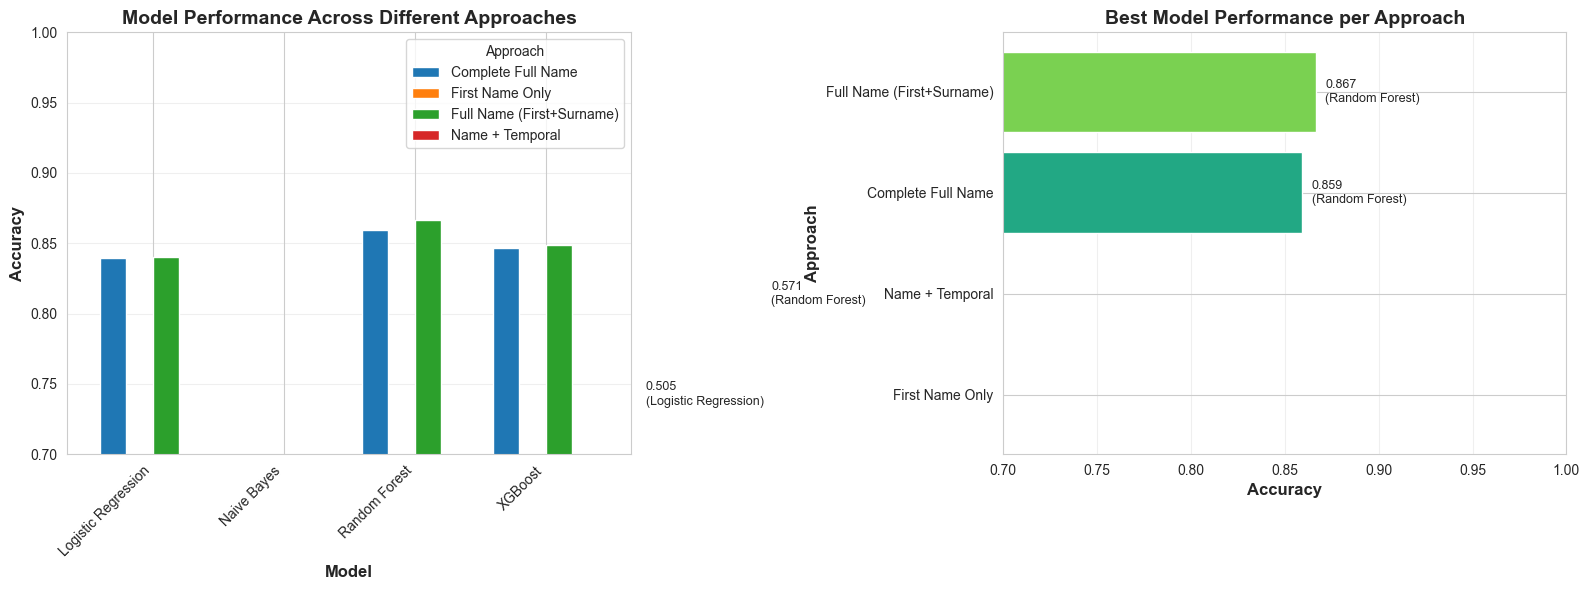


✓ Visualization complete!


In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)

# Create comparison plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Accuracy by Model and Approach
pivot_data = df_all_results.pivot(index='Model', columns='Approach', values='Accuracy')
pivot_data.plot(kind='bar', ax=ax1, width=0.8)
ax1.set_xlabel('Model', fontsize=12, fontweight='bold')
ax1.set_ylabel('Accuracy', fontsize=12, fontweight='bold')
ax1.set_title('Model Performance Across Different Approaches', fontsize=14, fontweight='bold')
ax1.legend(title='Approach', fontsize=10)
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45, ha='right')
ax1.grid(axis='y', alpha=0.3)
ax1.set_ylim([0.7, 1.0])  # Adjust range as needed

# Plot 2: Best model per approach
best_per_approach_sorted = best_per_approach.sort_values('Accuracy', ascending=True)
colors = sns.color_palette("viridis", len(best_per_approach_sorted))
ax2.barh(best_per_approach_sorted['Approach'], best_per_approach_sorted['Accuracy'], color=colors)
ax2.set_xlabel('Accuracy', fontsize=12, fontweight='bold')
ax2.set_ylabel('Approach', fontsize=12, fontweight='bold')
ax2.set_title('Best Model Performance per Approach', fontsize=14, fontweight='bold')
ax2.grid(axis='x', alpha=0.3)
ax2.set_xlim([0.7, 1.0])  # Adjust range as needed

# Add accuracy labels on bars
for i, (idx, row) in enumerate(best_per_approach_sorted.iterrows()):
    ax2.text(row['Accuracy'] + 0.005, i, f"{row['Accuracy']:.3f}\n({row['Model']})", 
             va='center', fontsize=9)

plt.tight_layout()
plt.show()

print("\n✓ Visualization complete!")

### 9.8.7. Key Insights and Recommendations

Let's analyze what we learned from these different approaches.

In [30]:
print("="*70)
print("KEY INSIGHTS FROM DIFFERENT APPROACHES")
print("="*70)

insights = []

# Compare dataset sizes
print("\n1. DATASET AVAILABILITY:")
print(f"   - First Name Only: {len(X_train)} training samples")
print(f"   - Full Name: {len(X_train_full)} training samples")
print(f"   - With Temporal Features: {len(X_train_names)} training samples")

dataset_reduction = (len(X_train) - len(X_train_full)) / len(X_train) * 100
print(f"\n   → Using full names reduces dataset by {dataset_reduction:.1f}%")
print(f"     (fewer people have both forename and surname)")

# Compare best accuracies
print("\n2. PERFORMANCE COMPARISON:")
best_firstname = max(r['accuracy'] for r in results.values())
best_fullname = max(r['accuracy'] for r in results_full.values())

# Check if complete full name results exist
if 'results_complete_full' in dir() and results_complete_full:
    best_complete_fullname = max(r['accuracy'] for r in results_complete_full.values())
else:
    best_complete_fullname = None

if 'results_temporal' in dir() and results_temporal:
    best_temporal = max(r['accuracy'] for r in results_temporal.values())
else:
    best_temporal = None

print(f"   - Best with First Name Only: {best_firstname:.4f}")
print(f"   - Best with Full Name (First+Surname): {best_fullname:.4f}")
if best_complete_fullname is not None:
    print(f"   - Best with Complete Full Name: {best_complete_fullname:.4f}")
if best_temporal is not None:
    print(f"   - Best with Temporal Features: {best_temporal:.4f}")

improvement_full = (best_fullname - best_firstname) * 100
print(f"\n   → Full name (first+surname) improves accuracy by: {improvement_full:+.2f} percentage points")

if best_complete_fullname is not None:
    improvement_complete = (best_complete_fullname - best_firstname) * 100
    improvement_complete_vs_first = (best_complete_fullname - best_fullname) * 100
    print(f"   → Complete full name improves over first-only by: {improvement_complete:+.2f} percentage points")
    print(f"   → Complete full name vs first+surname: {improvement_complete_vs_first:+.2f} percentage points")

if best_temporal is not None:
    improvement_temporal = (best_temporal - best_firstname) * 100
    print(f"   → Temporal features improve accuracy by: {improvement_temporal:+.2f} percentage points")

# Model comparison
print("\n3. MODEL COMPARISON:")
model_performances = {}
approach_results_list = [results, results_full]
if 'results_complete_full' in dir() and results_complete_full:
    approach_results_list.append(results_complete_full)
if 'results_temporal' in dir() and results_temporal:
    approach_results_list.append(results_temporal)

for approach_results in approach_results_list:
    for name, res in approach_results.items():
        model_name = name.split(' (')[0]  # Remove (Full) or (Temporal) or (Complete Full) suffix
        if model_name not in model_performances:
            model_performances[model_name] = []
        model_performances[model_name].append(res['accuracy'])

print("\n   Average accuracy across all approaches:")
for model_name in sorted(model_performances.keys()):
    avg_acc = np.mean(model_performances[model_name])
    print(f"   - {model_name:25} {avg_acc:.4f} ({avg_acc*100:.2f}%)")

# Recommendations
print("\n" + "="*70)
print("RECOMMENDATIONS")
print("="*70)

print("\n✓ Full names provide additional signal from surnames")
print("  → Consider using when available, but be aware of reduced dataset")
if best_complete_fullname is not None and best_fullname is not None:
    if best_complete_fullname > best_fullname:
        print("  → Complete forename (all parts) performs better than first name only")
    else:
        print("  → First name only + surname is sufficient; additional forename parts don't help much")

if best_temporal is not None:
    print("\n✓ Temporal features can help, especially for historical datasets")
    print("  → Birth/death dates provide contextual information")
    print("  → Century and decade features capture historical naming patterns")

print("\n✓ Model selection insights:")
if 'XGBoost' in model_performances:
    xgb_avg = np.mean(model_performances['XGBoost'])
    lr_avg = np.mean(model_performances['Logistic Regression'])
    rf_avg = np.mean(model_performances['Random Forest'])
    
    if xgb_avg > lr_avg and xgb_avg > rf_avg:
        print("  → XGBoost performs best on average - good for complex patterns")
    elif lr_avg > xgb_avg and lr_avg > rf_avg:
        print("  → Logistic Regression performs best - simpler and more interpretable")
    else:
        print("  → Random Forest performs best - good balance of complexity")
        
print("\n✓ For production use, consider:")
print("  → Use full name + temporal features when available")
print("  → Fall back to first name only when surname/dates missing")
print("  → Ensemble multiple models for best results")

KEY INSIGHTS FROM DIFFERENT APPROACHES

1. DATASET AVAILABILITY:
   - First Name Only: 418 training samples
   - Full Name: 1800 training samples
   - With Temporal Features: 418 training samples

   → Using full names reduces dataset by -330.6%
     (fewer people have both forename and surname)

2. PERFORMANCE COMPARISON:
   - Best with First Name Only: 0.5048
   - Best with Full Name (First+Surname): 0.8667
   - Best with Complete Full Name: 0.8593
   - Best with Temporal Features: 0.5714

   → Full name (first+surname) improves accuracy by: +36.19 percentage points
   → Complete full name improves over first-only by: +35.45 percentage points
   → Complete full name vs first+surname: -0.74 percentage points
   → Temporal features improve accuracy by: +6.67 percentage points

3. MODEL COMPARISON:

   Average accuracy across all approaches:
   - Logistic Regression       0.6747 (67.47%)
   - Naive Bayes               0.4857 (48.57%)
   - Random Forest             0.6982 (69.82%)
   - X

# 10. Comprehensive Data & Results Visualizations

Visual overview of the dataset composition and classifier performance.

## 10.1. Dataset Overview

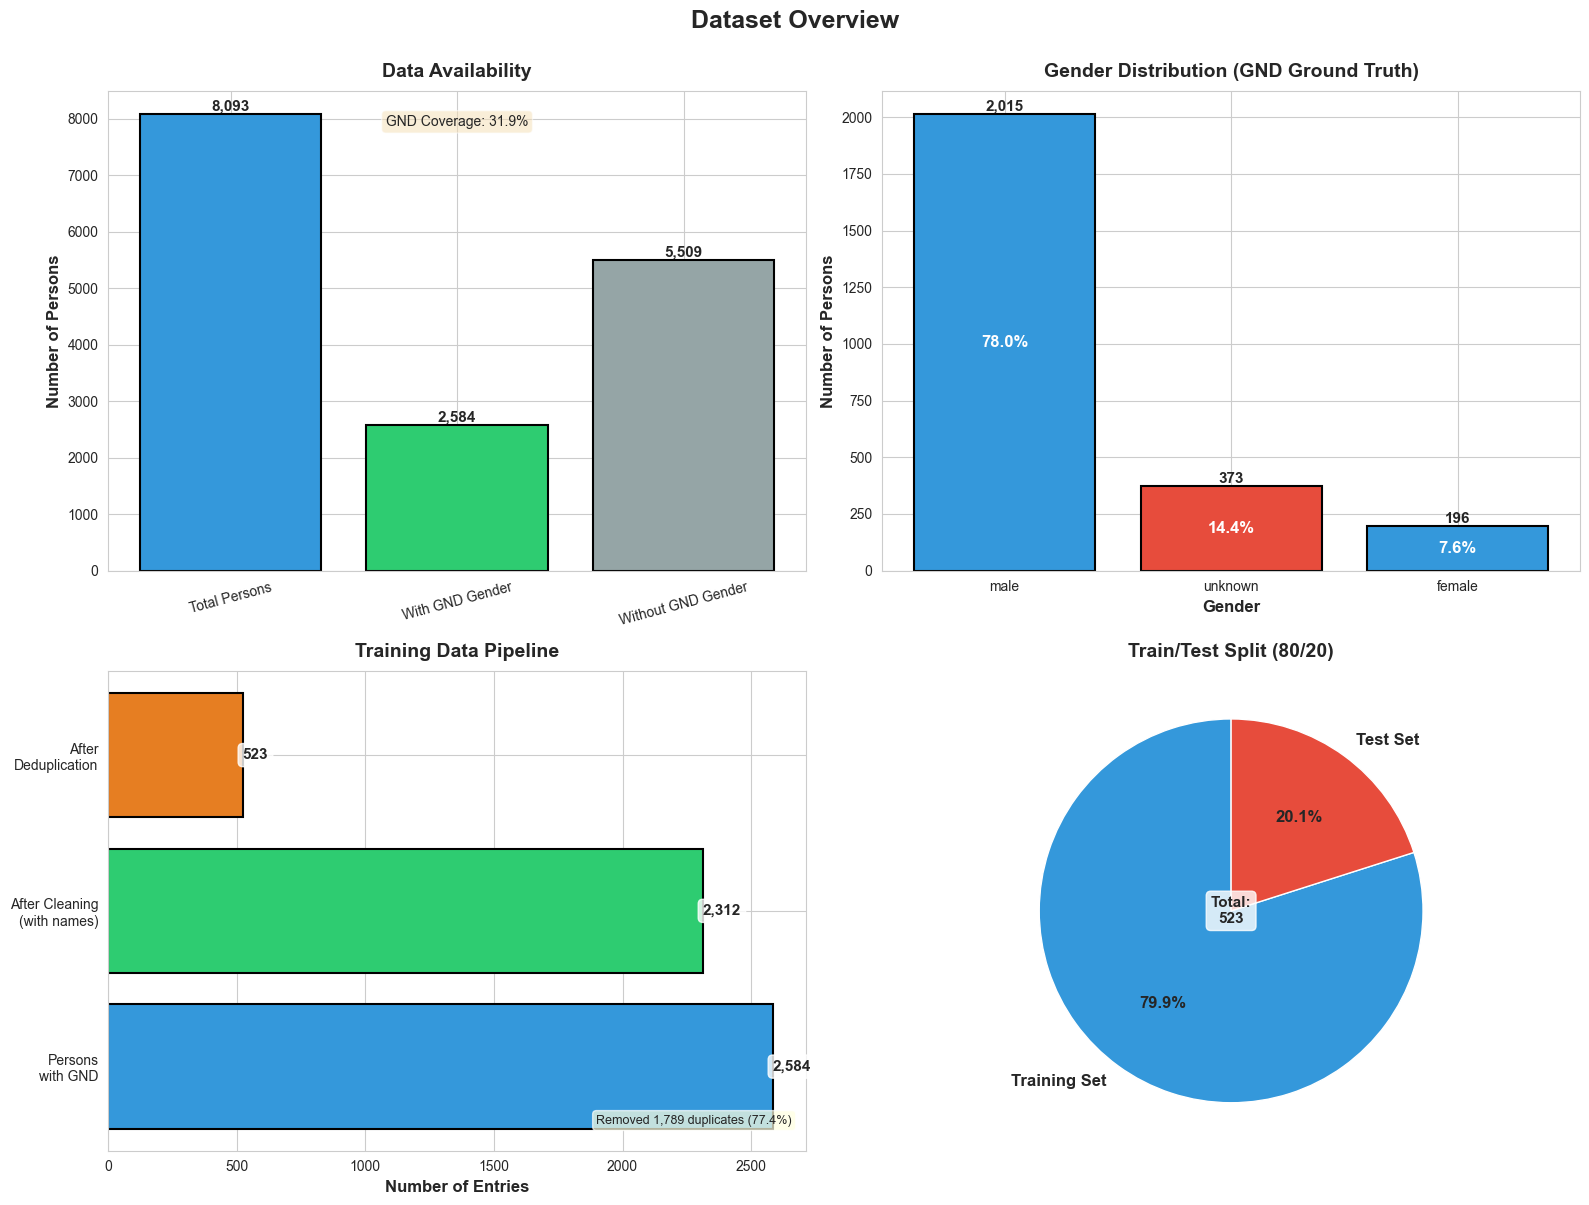

✓ Dataset overview visualization complete!


In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set style for all plots
sns.set_style("whitegrid")
sns.set_palette("husl")

# Create figure with subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Dataset Overview', fontsize=18, fontweight='bold', y=1.00)

# Colors
colors_overview = ['#3498db', '#2ecc71', '#95a5a6']
colors_gender = ['#3498db', '#e74c3c']

# ============================================================================
# 1. Total Entries vs GND Data Available
# ============================================================================
ax1 = axes[0, 0]

total_persons = len(df_persons)
persons_with_gnd = df_persons['gnd_gender'].notna().sum()
persons_without_gnd = total_persons - persons_with_gnd

data_availability = pd.DataFrame({
    'Category': ['Total Persons', 'With GND Gender', 'Without GND Gender'],
    'Count': [total_persons, persons_with_gnd, persons_without_gnd]
})

bars1 = ax1.bar(data_availability['Category'], data_availability['Count'], 
                color=colors_overview, edgecolor='black', linewidth=1.5)
ax1.set_ylabel('Number of Persons', fontsize=12, fontweight='bold')
ax1.set_title('Data Availability', fontsize=14, fontweight='bold', pad=10)
ax1.tick_params(axis='x', rotation=15)

# Add value labels on bars
for bar in bars1:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height):,}',
             ha='center', va='bottom', fontsize=11, fontweight='bold')

# Add percentage for GND coverage
coverage_pct = (persons_with_gnd / total_persons) * 100
ax1.text(0.5, 0.95, f'GND Coverage: {coverage_pct:.1f}%',
         transform=ax1.transAxes, ha='center', va='top',
         fontsize=10, bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# ============================================================================
# 2. Gender Distribution (GND Data)
# ============================================================================
ax2 = axes[0, 1]

gender_counts = df_persons['gnd_gender'].value_counts()
bars2 = ax2.bar(gender_counts.index, gender_counts.values, 
                color=colors_gender, edgecolor='black', linewidth=1.5)
ax2.set_ylabel('Number of Persons', fontsize=12, fontweight='bold')
ax2.set_title('Gender Distribution (GND Ground Truth)', fontsize=14, fontweight='bold', pad=10)
ax2.set_xlabel('Gender', fontsize=12, fontweight='bold')

# Add value labels on bars
for bar in bars2:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height):,}',
             ha='center', va='bottom', fontsize=11, fontweight='bold')

# Add percentages
for i, (gender, count) in enumerate(gender_counts.items()):
    pct = (count / persons_with_gnd) * 100
    ax2.text(i, count * 0.5, f'{pct:.1f}%',
             ha='center', va='center', fontsize=12, fontweight='bold', color='white')

# ============================================================================
# 3. Training Data Pipeline (with deduplication)
# ============================================================================
ax3 = axes[1, 0]

# Calculate pipeline statistics
if 'df_train_dedup' in dir():
    train_before_dedup = len(df_train)
    train_after_dedup = len(df_train_dedup)
else:
    train_before_dedup = persons_with_gnd
    train_after_dedup = persons_with_gnd

pipeline_data = pd.DataFrame({
    'Stage': ['Persons\nwith GND', 'After Cleaning\n(with names)', 'After\nDeduplication'],
    'Count': [persons_with_gnd, train_before_dedup, train_after_dedup]
})

bars3 = ax3.barh(pipeline_data['Stage'], pipeline_data['Count'], 
                 color=['#3498db', '#2ecc71', '#e67e22'], 
                 edgecolor='black', linewidth=1.5)
ax3.set_xlabel('Number of Entries', fontsize=12, fontweight='bold')
ax3.set_title('Training Data Pipeline', fontsize=14, fontweight='bold', pad=10)

# Add value labels on bars
for i, bar in enumerate(bars3):
    width = bar.get_width()
    ax3.text(width, bar.get_y() + bar.get_height()/2.,
             f'{int(width):,}',
             ha='left', va='center', fontsize=11, fontweight='bold', 
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# Add reduction annotations
if train_before_dedup > train_after_dedup:
    reduction = train_before_dedup - train_after_dedup
    reduction_pct = (reduction / train_before_dedup) * 100
    ax3.text(0.98, 0.05, f'Removed {reduction:,} duplicates ({reduction_pct:.1f}%)',
             transform=ax3.transAxes, ha='right', va='bottom',
             fontsize=9, bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.7))

# ============================================================================
# 4. Train/Test Split Distribution
# ============================================================================
ax4 = axes[1, 1]

# Get train/test split info
if 'y_train' in dir() and 'y_test' in dir():
    train_size = len(y_train)
    test_size = len(y_test)
    
    split_data = pd.DataFrame({
        'Split': ['Training Set', 'Test Set'],
        'Count': [train_size, test_size]
    })
    
    # Create pie chart
    colors_split = ['#3498db', '#e74c3c']
    wedges, texts, autotexts = ax4.pie(split_data['Count'], 
                                         labels=split_data['Split'],
                                         autopct='%1.1f%%',
                                         colors=colors_split,
                                         startangle=90,
                                         textprops={'fontsize': 12, 'fontweight': 'bold'})
    
    # Add count to center
    total = train_size + test_size
    ax4.text(0, 0, f'Total:\n{total:,}',
             ha='center', va='center', fontsize=11, fontweight='bold',
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    
    ax4.set_title('Train/Test Split (80/20)', fontsize=14, fontweight='bold', pad=10)
else:
    ax4.text(0.5, 0.5, 'Train/Test split not yet performed',
             ha='center', va='center', transform=ax4.transAxes,
             fontsize=12)
    ax4.set_title('Train/Test Split', fontsize=14, fontweight='bold', pad=10)

plt.tight_layout()
plt.show()

print("✓ Dataset overview visualization complete!")

## 10.2. Classifier Results Comparison

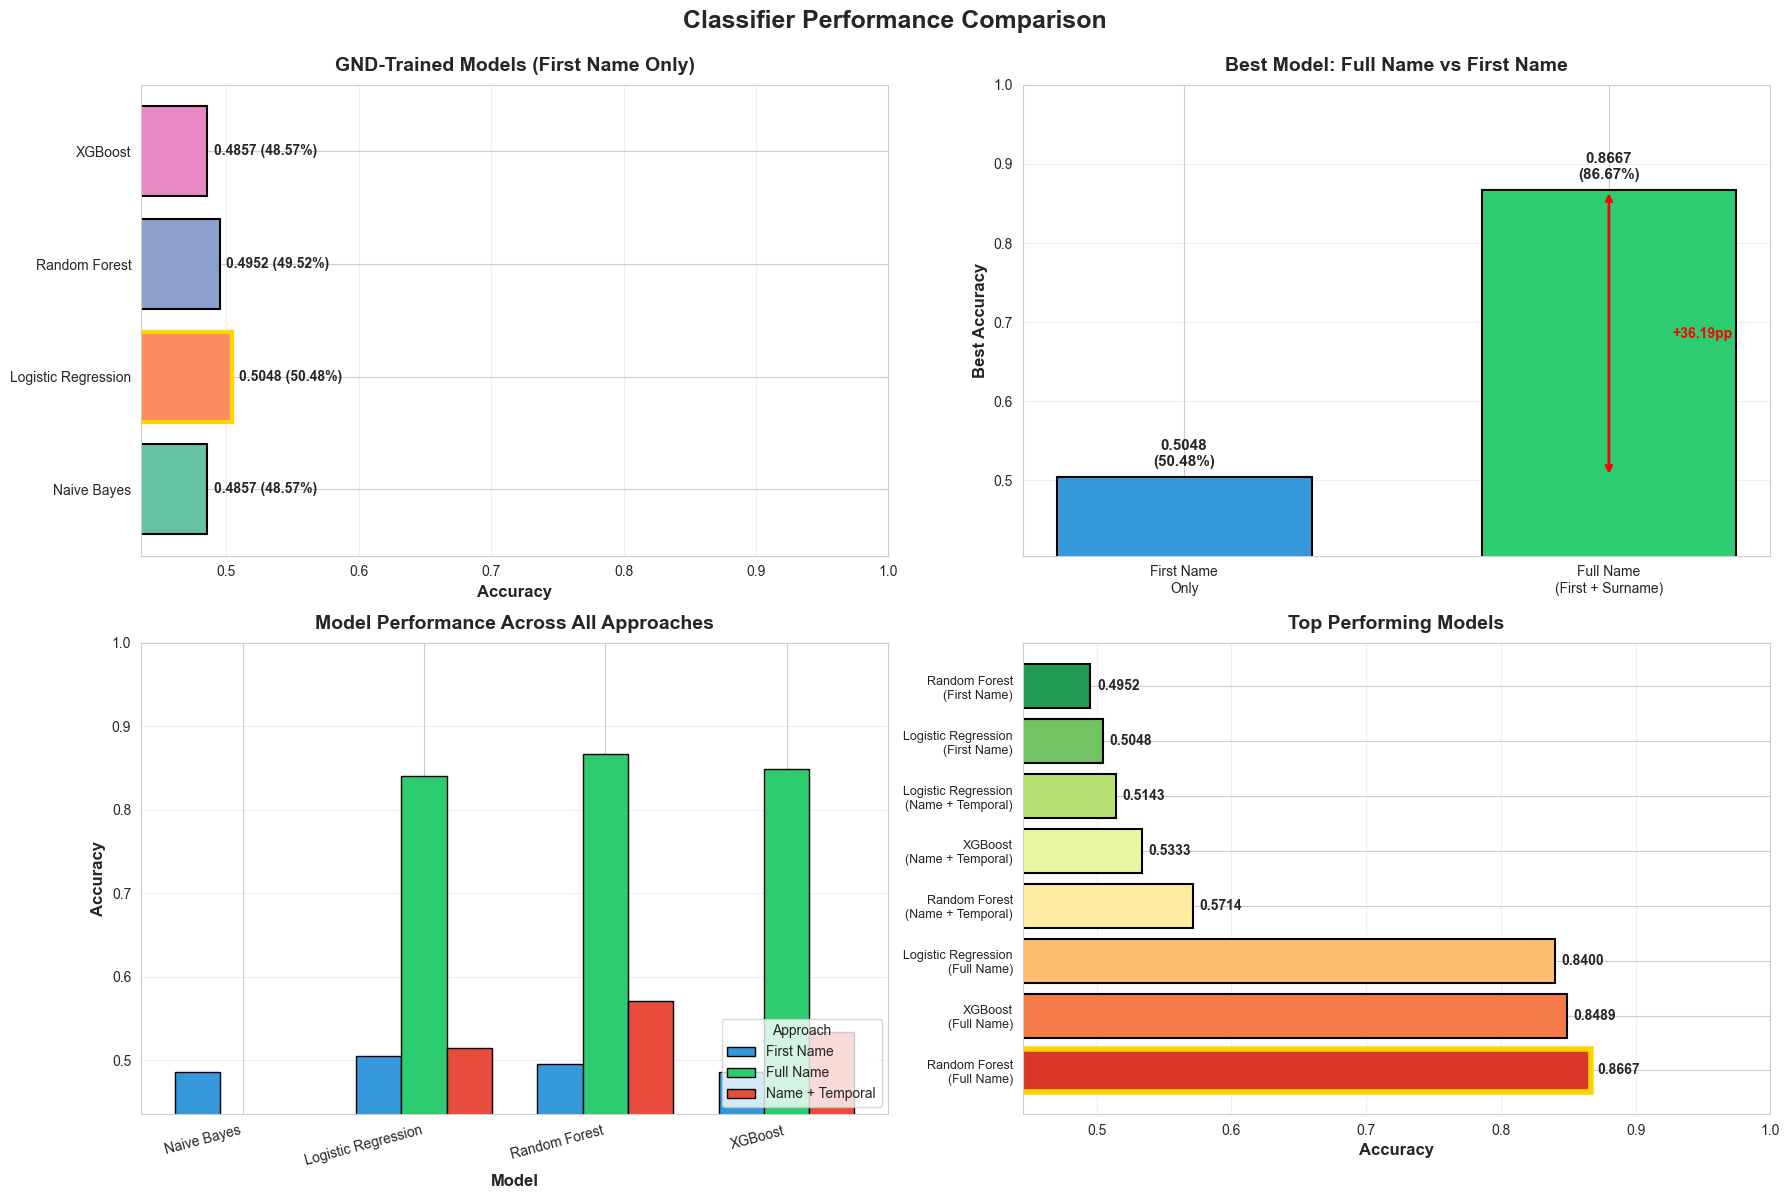

✓ Classifier results visualization complete!


In [37]:
# Visualize classifier performance
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle('Classifier Performance Comparison', fontsize=18, fontweight='bold', y=0.995)

# ============================================================================
# 1. GND-Trained Models Performance (First Name Only)
# ============================================================================
ax1 = axes[0, 0]

if 'results' in dir() and results:
    model_names = list(results.keys())
    accuracies = [results[name]['accuracy'] for name in model_names]
    
    # Determine appropriate y-axis limits
    min_acc = min(accuracies)
    y_min = max(0, min_acc - 0.05)  # 5% buffer below minimum
    
    colors_models = sns.color_palette("Set2", len(model_names))
    bars = ax1.barh(model_names, accuracies, color=colors_models, 
                    edgecolor='black', linewidth=1.5)
    
    ax1.set_xlabel('Accuracy', fontsize=12, fontweight='bold')
    ax1.set_title('GND-Trained Models (First Name Only)', fontsize=14, fontweight='bold', pad=10)
    ax1.set_xlim([y_min, 1.0])
    ax1.grid(axis='x', alpha=0.3)
    
    # Add accuracy labels
    for i, (bar, acc) in enumerate(zip(bars, accuracies)):
        ax1.text(acc + 0.005, bar.get_y() + bar.get_height()/2.,
                 f'{acc:.4f} ({acc*100:.2f}%)',
                 ha='left', va='center', fontsize=10, fontweight='bold')
    
    # Highlight best model
    best_idx = np.argmax(accuracies)
    bars[best_idx].set_edgecolor('gold')
    bars[best_idx].set_linewidth(3)
else:
    ax1.text(0.5, 0.5, 'Models not yet trained', ha='center', va='center',
             transform=ax1.transAxes, fontsize=12)
    ax1.set_title('GND-Trained Models (First Name Only)', fontsize=14, fontweight='bold', pad=10)

# ============================================================================
# 2. Full Name vs First Name Comparison
# ============================================================================
ax2 = axes[0, 1]

if 'results' in dir() and 'results_full' in dir() and results and results_full:
    # Compare best models from each approach
    best_firstname_acc = max(r['accuracy'] for r in results.values())
    best_fullname_acc = max(r['accuracy'] for r in results_full.values())
    
    comparison_data = pd.DataFrame({
        'Approach': ['First Name\nOnly', 'Full Name\n(First + Surname)'],
        'Best Accuracy': [best_firstname_acc, best_fullname_acc]
    })
    
    # Determine appropriate y-axis limits
    min_acc = min(comparison_data['Best Accuracy'])
    y_min = max(0, min_acc - 0.1)  # 10% buffer below minimum
    
    colors_approach = ['#3498db', '#2ecc71']
    bars = ax2.bar(comparison_data['Approach'], comparison_data['Best Accuracy'],
                   color=colors_approach, edgecolor='black', linewidth=1.5, width=0.6)
    
    ax2.set_ylabel('Best Accuracy', fontsize=12, fontweight='bold')
    ax2.set_title('Best Model: Full Name vs First Name', fontsize=14, fontweight='bold', pad=10)
    ax2.set_ylim([y_min, 1.0])
    ax2.grid(axis='y', alpha=0.3)
    
    # Add accuracy labels
    for bar, acc in zip(bars, comparison_data['Best Accuracy']):
        ax2.text(bar.get_x() + bar.get_width()/2., acc + 0.01,
                 f'{acc:.4f}\n({acc*100:.2f}%)',
                 ha='center', va='bottom', fontsize=11, fontweight='bold')
    
    # Show improvement
    improvement = best_fullname_acc - best_firstname_acc
    if improvement > 0:
        ax2.annotate('', xy=(1, best_fullname_acc), xytext=(1, best_firstname_acc),
                    arrowprops=dict(arrowstyle='<->', color='red', lw=2))
        ax2.text(1.15, (best_firstname_acc + best_fullname_acc) / 2,
                f'+{improvement*100:.2f}pp',
                ha='left', va='center', fontsize=10, color='red', fontweight='bold')
else:
    ax2.text(0.5, 0.5, 'Full name models not yet trained', ha='center', va='center',
             transform=ax2.transAxes, fontsize=12)
    ax2.set_title('Best Model: Full Name vs First Name', fontsize=14, fontweight='bold', pad=10)

# ============================================================================
# 3. All Approaches Combined (if available)
# ============================================================================
ax3 = axes[1, 0]

try:
    # Try to build comprehensive comparison
    all_model_data = []
    
    if 'results' in dir() and results:
        for name, res in results.items():
            all_model_data.append({
                'Model': name,
                'Approach': 'First Name',
                'Accuracy': res['accuracy']
            })
    
    if 'results_full' in dir() and results_full:
        for name, res in results_full.items():
            model_name = name.replace(' (Full)', '')
            all_model_data.append({
                'Model': model_name,
                'Approach': 'Full Name',
                'Accuracy': res['accuracy']
            })
    
    if 'results_temporal' in dir() and results_temporal:
        for name, res in results_temporal.items():
            model_name = name.replace(' (Temporal)', '')
            all_model_data.append({
                'Model': model_name,
                'Approach': 'Name + Temporal',
                'Accuracy': res['accuracy']
            })
    
    if all_model_data:
        df_all_models = pd.DataFrame(all_model_data)
        
        # Create grouped bar chart
        approaches = df_all_models['Approach'].unique()
        models = df_all_models['Model'].unique()
        
        # Determine appropriate y-axis limits
        min_acc = df_all_models['Accuracy'].min()
        y_min = max(0, min_acc - 0.05)
        
        x = np.arange(len(models))
        width = 0.25
        
        colors_dict = {
            'First Name': '#3498db',
            'Full Name': '#2ecc71', 
            'Name + Temporal': '#e74c3c'
        }
        
        for i, approach in enumerate(approaches):
            approach_data = df_all_models[df_all_models['Approach'] == approach]
            # Build a proper mapping for each model
            accuracies = []
            for model in models:
                model_data = approach_data[approach_data['Model'] == model]
                if len(model_data) > 0:
                    accuracies.append(model_data['Accuracy'].values[0])
                else:
                    accuracies.append(0)  # No data for this combination
            
            # Only plot bars where we have data (accuracy > 0)
            x_positions = [x[j] + i*width for j in range(len(models)) if accuracies[j] > 0]
            y_values = [acc for acc in accuracies if acc > 0]
            
            color = colors_dict.get(approach, '#95a5a6')
            ax3.bar(x_positions, y_values, width, label=approach, 
                   edgecolor='black', linewidth=1, color=color)
        
        ax3.set_xlabel('Model', fontsize=12, fontweight='bold')
        ax3.set_ylabel('Accuracy', fontsize=12, fontweight='bold')
        ax3.set_title('Model Performance Across All Approaches', fontsize=14, fontweight='bold', pad=10)
        ax3.set_xticks(x + width)
        ax3.set_xticklabels(models, rotation=15, ha='right')
        ax3.legend(title='Approach', fontsize=10, loc='lower right')
        ax3.set_ylim([y_min, 1.0])
        ax3.grid(axis='y', alpha=0.3)
    else:
        ax3.text(0.5, 0.5, 'No model results available yet', ha='center', va='center',
                transform=ax3.transAxes, fontsize=12)
        ax3.set_title('Model Performance Across All Approaches', fontsize=14, fontweight='bold', pad=10)
        
except Exception as e:
    ax3.text(0.5, 0.5, f'Error creating comparison:\n{str(e)}', ha='center', va='center',
             transform=ax3.transAxes, fontsize=10)
    ax3.set_title('Model Performance Across All Approaches', fontsize=14, fontweight='bold', pad=10)

# ============================================================================
# 4. Overall Best Models Leaderboard
# ============================================================================
ax4 = axes[1, 1]

try:
    if all_model_data:
        # Get top 8 models
        df_all_models_sorted = df_all_models.sort_values('Accuracy', ascending=False).head(8)
        
        # Determine appropriate x-axis limits
        min_acc = df_all_models_sorted['Accuracy'].min()
        x_min = max(0, min_acc - 0.05)
        
        colors_leaderboard = sns.color_palette("RdYlGn", len(df_all_models_sorted))
        bars = ax4.barh(range(len(df_all_models_sorted)), df_all_models_sorted['Accuracy'],
                       color=colors_leaderboard, edgecolor='black', linewidth=1.5)
        
        # Set y-axis labels with model and approach
        labels = [f"{row['Model']}\n({row['Approach']})" 
                 for _, row in df_all_models_sorted.iterrows()]
        ax4.set_yticks(range(len(df_all_models_sorted)))
        ax4.set_yticklabels(labels, fontsize=9)
        
        ax4.set_xlabel('Accuracy', fontsize=12, fontweight='bold')
        ax4.set_title('Top Performing Models', fontsize=14, fontweight='bold', pad=10)
        ax4.set_xlim([x_min, 1.0])
        ax4.grid(axis='x', alpha=0.3)
        
        # Add accuracy labels
        for i, (bar, acc) in enumerate(zip(bars, df_all_models_sorted['Accuracy'])):
            ax4.text(acc + 0.005, bar.get_y() + bar.get_height()/2.,
                    f'{acc:.4f}',
                    ha='left', va='center', fontsize=10, fontweight='bold')
        
        # Add gold border to best model
        bars[0].set_edgecolor('gold')
        bars[0].set_linewidth(4)
    else:
        ax4.text(0.5, 0.5, 'No model results available', ha='center', va='center',
                transform=ax4.transAxes, fontsize=12)
        ax4.set_title('Top Performing Models', fontsize=14, fontweight='bold', pad=10)
        
except Exception as e:
    ax4.text(0.5, 0.5, f'Error creating leaderboard:\n{str(e)}', ha='center', va='center',
             transform=ax4.transAxes, fontsize=10)
    ax4.set_title('Top Performing Models', fontsize=14, fontweight='bold', pad=10)

plt.tight_layout()
plt.show()

print("✓ Classifier results visualization complete!")

## 10.3. Gender Prediction Distribution

How many persons were classified by each method, and the gender distribution of predictions.

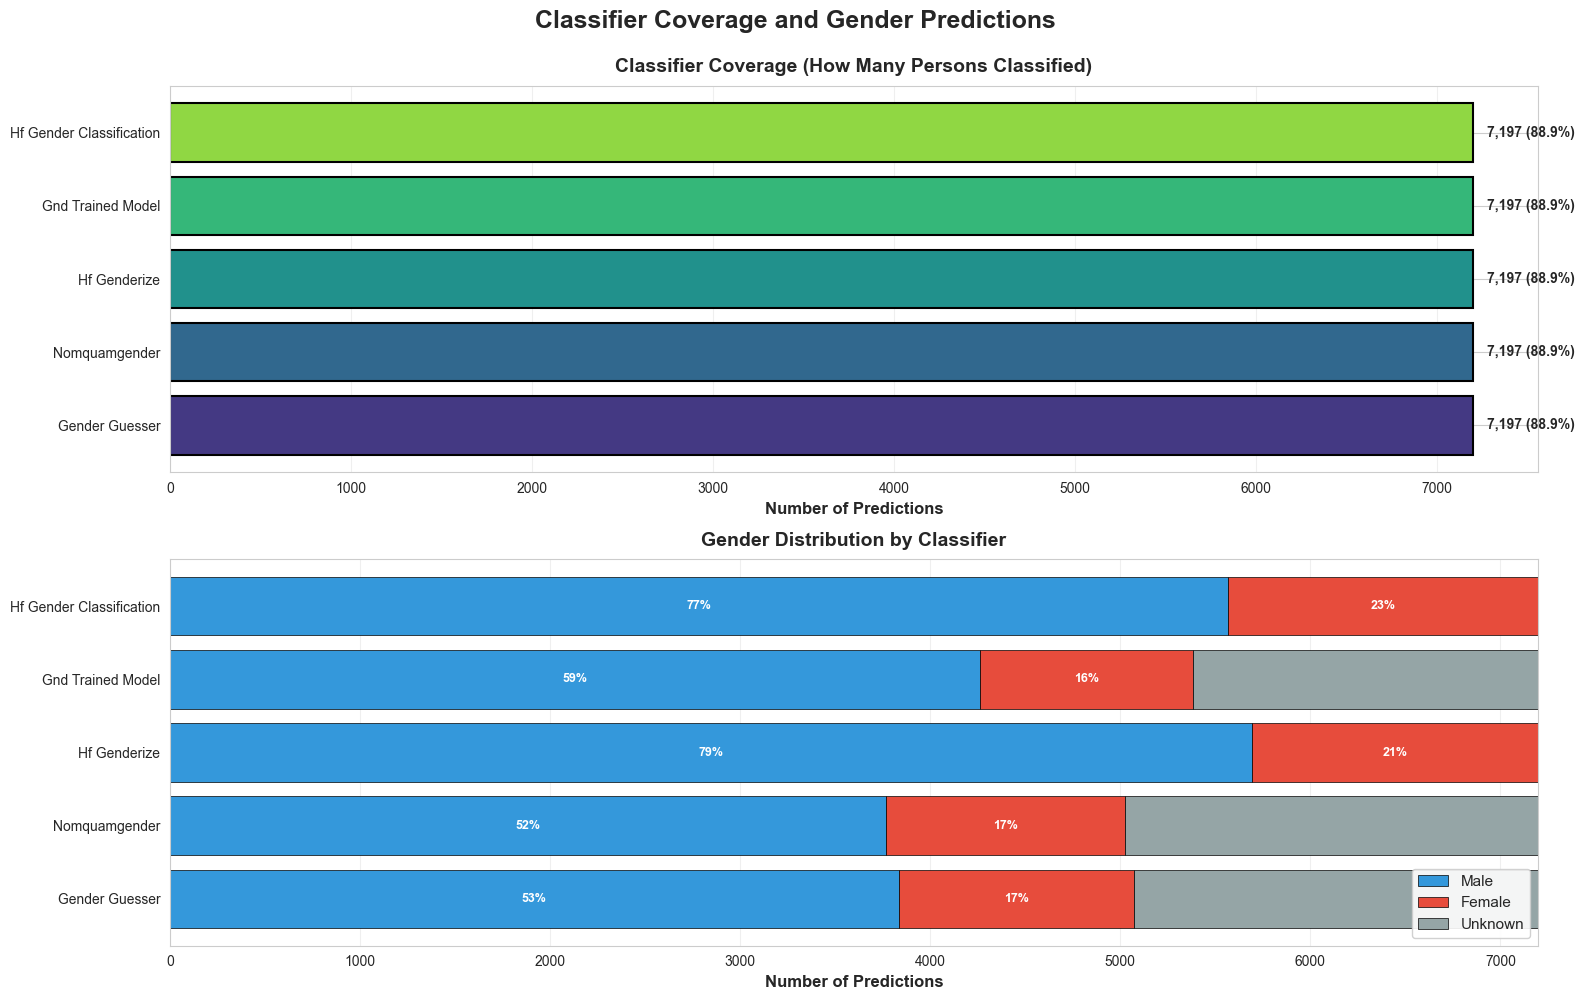

✓ Prediction distribution visualization complete!


In [38]:
# Visualize prediction coverage and gender distribution
fig, axes = plt.subplots(2, 1, figsize=(16, 10))
fig.suptitle('Classifier Coverage and Gender Predictions', fontsize=18, fontweight='bold', y=0.995)

# Get all classifier columns
classifier_columns = [col for col in df_persons.columns 
                     if col in ['gender_guesser', 'nomquamgender', 'hf_genderize', 
                               'hf_gender_classification', 'gnd_trained_model'] 
                     or col.startswith('llm_')]

# ============================================================================
# 1. Coverage: How many persons were classified by each method
# ============================================================================
ax1 = axes[0]

if classifier_columns:
    coverage_data = []
    
    for clf in classifier_columns:
        total_predictions = df_persons[clf].notna().sum()
        coverage_pct = (total_predictions / len(df_persons)) * 100
        
        coverage_data.append({
            'Classifier': clf.replace('_', ' ').title(),
            'Predictions': total_predictions,
            'Coverage %': coverage_pct
        })
    
    df_coverage = pd.DataFrame(coverage_data).sort_values('Predictions', ascending=True)
    
    colors_coverage = sns.color_palette("viridis", len(df_coverage))
    bars = ax1.barh(df_coverage['Classifier'], df_coverage['Predictions'],
                    color=colors_coverage, edgecolor='black', linewidth=1.5)
    
    ax1.set_xlabel('Number of Predictions', fontsize=12, fontweight='bold')
    ax1.set_title('Classifier Coverage (How Many Persons Classified)', fontsize=14, fontweight='bold', pad=10)
    ax1.grid(axis='x', alpha=0.3)
    
    # Add labels with counts and percentages
    for i, (bar, row) in enumerate(zip(bars, df_coverage.itertuples())):
        ax1.text(row.Predictions + len(df_persons)*0.01, bar.get_y() + bar.get_height()/2.,
                f"{row.Predictions:,} ({row._3:.1f}%)",
                ha='left', va='center', fontsize=10, fontweight='bold')
else:
    ax1.text(0.5, 0.5, 'No classifier predictions available', ha='center', va='center',
             transform=ax1.transAxes, fontsize=12)
    ax1.set_title('Classifier Coverage', fontsize=14, fontweight='bold', pad=10)

# ============================================================================
# 2. Gender Distribution by Classifier
# ============================================================================
ax2 = axes[1]

if classifier_columns:
    # Prepare data for stacked bar chart
    gender_dist_data = []
    
    for clf in classifier_columns:
        clf_predictions = df_persons[clf].dropna()
        if len(clf_predictions) > 0:
            value_counts = clf_predictions.value_counts()
            
            # Get counts for each gender (handle missing genders)
            male_count = value_counts.get('male', 0)
            female_count = value_counts.get('female', 0)
            unknown_count = value_counts.get('unknown', 0)
            
            gender_dist_data.append({
                'Classifier': clf.replace('_', ' ').title(),
                'Male': male_count,
                'Female': female_count,
                'Unknown': unknown_count
            })
    
    df_gender_dist = pd.DataFrame(gender_dist_data)
    
    # Sort by total predictions
    df_gender_dist['Total'] = df_gender_dist['Male'] + df_gender_dist['Female'] + df_gender_dist['Unknown']
    df_gender_dist = df_gender_dist.sort_values('Total', ascending=True)
    
    # Create stacked horizontal bar chart
    classifiers = df_gender_dist['Classifier']
    x_pos = np.arange(len(classifiers))
    
    colors_gender_dist = ['#3498db', '#e74c3c', '#95a5a6']
    
    bars_male = ax2.barh(x_pos, df_gender_dist['Male'], 
                        color=colors_gender_dist[0], label='Male', 
                        edgecolor='black', linewidth=0.5)
    bars_female = ax2.barh(x_pos, df_gender_dist['Female'], 
                          left=df_gender_dist['Male'],
                          color=colors_gender_dist[1], label='Female',
                          edgecolor='black', linewidth=0.5)
    bars_unknown = ax2.barh(x_pos, df_gender_dist['Unknown'],
                           left=df_gender_dist['Male'] + df_gender_dist['Female'],
                           color=colors_gender_dist[2], label='Unknown',
                           edgecolor='black', linewidth=0.5)
    
    ax2.set_yticks(x_pos)
    ax2.set_yticklabels(classifiers)
    ax2.set_xlabel('Number of Predictions', fontsize=12, fontweight='bold')
    ax2.set_title('Gender Distribution by Classifier', fontsize=14, fontweight='bold', pad=10)
    ax2.legend(loc='lower right', fontsize=11, framealpha=0.9)
    ax2.grid(axis='x', alpha=0.3)
    
    # Add percentage labels for male/female (skip unknown if too small)
    for i, row in df_gender_dist.iterrows():
        total = row['Total']
        if total > 0:
            # Male percentage
            male_pct = (row['Male'] / total) * 100
            if male_pct > 5:  # Only show if > 5%
                ax2.text(row['Male']/2, i, f"{male_pct:.0f}%",
                        ha='center', va='center', fontsize=9, 
                        fontweight='bold', color='white')
            
            # Female percentage
            female_pct = (row['Female'] / total) * 100
            if female_pct > 5:
                ax2.text(row['Male'] + row['Female']/2, i, f"{female_pct:.0f}%",
                        ha='center', va='center', fontsize=9,
                        fontweight='bold', color='white')
else:
    ax2.text(0.5, 0.5, 'No classifier predictions available', ha='center', va='center',
             transform=ax2.transAxes, fontsize=12)
    ax2.set_title('Gender Distribution by Classifier', fontsize=14, fontweight='bold', pad=10)

plt.tight_layout()
plt.show()

print("✓ Prediction distribution visualization complete!")

## 10.4. Summary Statistics Table

In [39]:
print("="*80)
print("COMPREHENSIVE SUMMARY STATISTICS")
print("="*80)

# Dataset statistics
print("\n📊 DATASET OVERVIEW")
print("-" * 80)
print(f"Total Persons in Dataset:        {len(df_persons):>8,}")
print(f"Persons with GND Gender:         {df_persons['gnd_gender'].notna().sum():>8,} ({(df_persons['gnd_gender'].notna().sum()/len(df_persons)*100):>5.1f}%)")
print(f"  - Male:                        {(df_persons['gnd_gender'] == 'male').sum():>8,}")
print(f"  - Female:                      {(df_persons['gnd_gender'] == 'female').sum():>8,}")

# Training data statistics
if 'df_train_dedup' in dir():
    print(f"\nTraining Data (after deduplication): {len(df_train_dedup):>8,}")
    if 'y_train' in dir():
        print(f"  - Training set:                  {len(y_train):>8,} ({len(y_train)/len(df_train_dedup)*100:>5.1f}%)")
        print(f"  - Test set:                      {len(y_test):>8,} ({len(y_test)/len(df_train_dedup)*100:>5.1f}%)")

# Classifier coverage
print("\n📈 CLASSIFIER COVERAGE")
print("-" * 80)
print(f"{'Classifier':<30} {'Predictions':>12} {'Coverage':>10}")
print("-" * 80)

for clf in classifier_columns:
    predictions = df_persons[clf].notna().sum()
    coverage = predictions / len(df_persons) * 100
    print(f"{clf:<30} {predictions:>12,} {coverage:>9.1f}%")

# Model performance (if available)
if 'results' in dir() and results:
    print("\n🏆 MODEL PERFORMANCE (GND-TRAINED)")
    print("-" * 80)
    print(f"{'Model':<30} {'Accuracy':>12} {'Test Samples':>15}")
    print("-" * 80)
    
    for name, res in sorted(results.items(), key=lambda x: x[1]['accuracy'], reverse=True):
        acc = res['accuracy']
        if 'y_test' in dir():
            n_test = len(y_test)
        else:
            n_test = 0
        print(f"{name:<30} {acc:>12.4f} {n_test:>15,}")

# Best models summary
print("\n⭐ BEST PERFORMING MODELS")
print("-" * 80)

best_models = []

if 'results' in dir() and results:
    best_firstname = max(results.items(), key=lambda x: x[1]['accuracy'])
    best_models.append(('First Name Only', best_firstname[0], best_firstname[1]['accuracy']))

if 'results_full' in dir() and results_full:
    best_fullname = max(results_full.items(), key=lambda x: x[1]['accuracy'])
    best_models.append(('Full Name', best_fullname[0], best_fullname[1]['accuracy']))

if 'results_temporal' in dir() and results_temporal:
    best_temporal = max(results_temporal.items(), key=lambda x: x[1]['accuracy'])
    best_models.append(('Name + Temporal', best_temporal[0], best_temporal[1]['accuracy']))

if best_models:
    print(f"{'Approach':<25} {'Model':<30} {'Accuracy':>12}")
    print("-" * 80)
    for approach, model, acc in sorted(best_models, key=lambda x: x[2], reverse=True):
        print(f"{approach:<25} {model:<30} {acc:>12.4f}")
    
    # Overall best
    overall_best = max(best_models, key=lambda x: x[2])
    print(f"\n🥇 OVERALL BEST: {overall_best[1]} ({overall_best[0]}) - {overall_best[2]:.4f}")

print("\n" + "="*80)
print("✓ Summary statistics complete!")
print("="*80)

COMPREHENSIVE SUMMARY STATISTICS

📊 DATASET OVERVIEW
--------------------------------------------------------------------------------
Total Persons in Dataset:           8,093
Persons with GND Gender:            2,584 ( 31.9%)
  - Male:                           2,015
  - Female:                           196

Training Data (after deduplication):      523
  - Training set:                       418 ( 79.9%)
  - Test set:                           105 ( 20.1%)

📈 CLASSIFIER COVERAGE
--------------------------------------------------------------------------------
Classifier                      Predictions   Coverage
--------------------------------------------------------------------------------
gender_guesser                        7,197      88.9%
nomquamgender                         7,197      88.9%
hf_genderize                          7,197      88.9%
gnd_trained_model                     7,197      88.9%
hf_gender_classification              7,197      88.9%

🏆 MODEL PERFORMANCE 